# Assignment 08 — Hussein Jawad
**E89 Deep Learning · RNNs and LSTMs for time series** (based on Lecture 8 and Géron, *Hands-On ML*, Ch. 14)

**Contents**
* Problem 1: predicting MSFT opening prices with the class RNN and LSTM code
* Problem 2: validation split, lookback windows of 10/30/60/120 days, and a five-day target
* Problem 3: neural machine translation with a vocabulary of 1,000 vs 3,000 words
* Appendix: how RNNs, LSTMs, layered LSTMs, bidirectional RNNs and encoder–decoders work

I ran this notebook on Google Colab with a T4 GPU. Run it from top to bottom: Problem 2 reuses the data,
model classes and settings from Problem 1.

---

# Problem 1: Predicting Microsoft (MSFT) opening prices with an RNN and an LSTM
Use the class notebooks `1_RNN_apple_stock_prediction` and `2_LSTM_apple_stock_prediction` with a company other than Apple:
train on its stock prices from January 2016 to September 6, 2026, then predict its opening prices from September 9 to October 10, 2026.


## Approach

#### Goal
Train a recurrent neural network on the daily opening prices of a company other than Apple, and use it to "predict" the opening
price for each trading day of a later period that the network has not seen.

#### Company and data
I chose Microsoft (ticker `MSFT`). It has been listed since 1986, so the full history from January 2016 is available.
I downloaded the prices from Yahoo Finance with the `yfinance` library.

| Data set | Requested period | Trading days in the data | Purpose |
|---|---|---|---|
| Training | Jan 1, 2016 to Sep 6, 2026 | 2,684 (Jan 4, 2016 – Sep 4, 2026) | The network learns from these prices |
| Test | Sep 9, 2026 to Oct 10, 2026 | 23 (Sep 9 – Oct 9, 2026) | Not used in training; only for checking the predictions |

Sep 6, 2026 is a Sunday and Oct 10, 2026 is a Saturday, so the last trading days in the two sets are Friday Sep 4 and Friday Oct 9.
The market was closed on Monday Sep 7 (Labor Day), and Tuesday Sep 8 is left out as the assignment specifies.

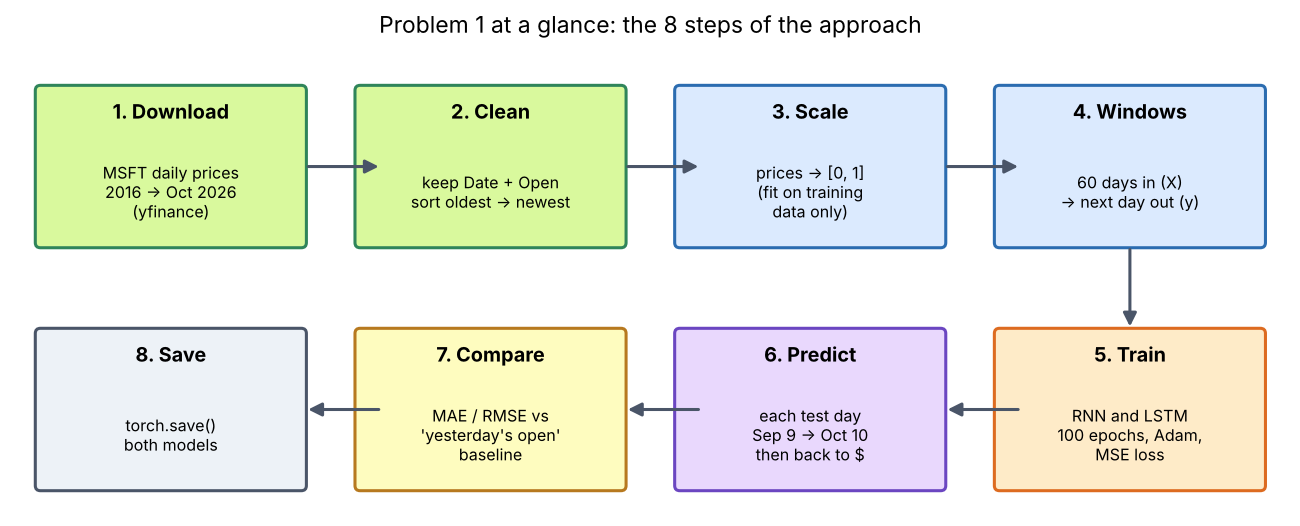

#### Steps
1. Download and clean the data. I keep only the date and the opening price, sorted from oldest to newest.
2. Scale the prices to 0–1 (the lowest training price becomes 0 and the highest becomes 1), since neural networks train better on
   small numbers. The scaler gets its min and max from the training data only, so nothing from the test period leaks into training.
3. Make training examples with a sliding window. Each example is 60 consecutive trading days (about 3 months) as the input and the
   next day's opening price as the target. Moving the window forward one day at a time gives 2,624 examples (see Appendix A.5).
4. Build the models from class: 4 stacked recurrent layers with 50 units each, dropout of 0.2 after each layer (randomly turning off
   20% of the units during training to reduce overfitting), and a linear layer that outputs the predicted price. Part A uses the vanilla
   RNN from class notebook 1 and Part B the LSTM from class notebook 2.
5. Train each model for 100 epochs with the Adam optimizer and mean squared error (MSE) loss, using the training loop from its class
   notebook (the RNN notebook clips the gradients to keep training stable; the LSTM notebook does not).
6. Predict the test period one day at a time (rolling one-step-ahead). For each test day the model gets the 60 actual prices before
   that day and predicts that day only. It does not forecast the whole month from September 4.

   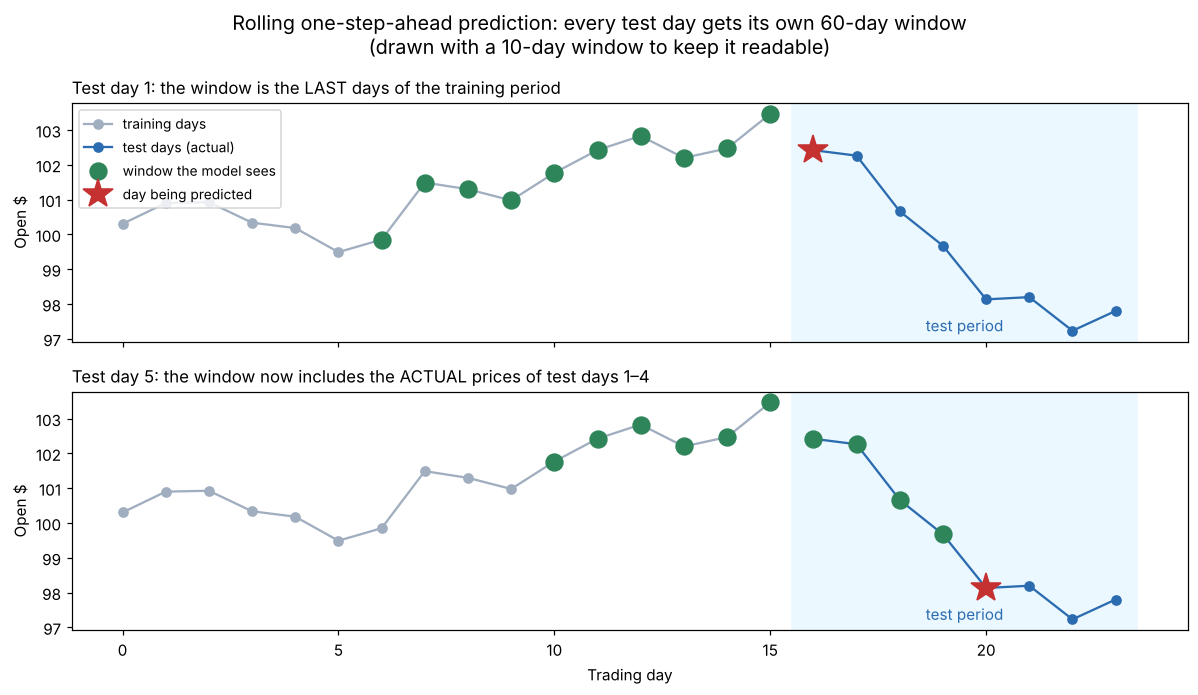
7. Convert the predictions back to dollars and compare them with a baseline.
   * MAE (mean absolute error) is the average miss in dollars. For example, an MAE of \$3 means the prediction is off by about \$3 on a typical day.
   * RMSE (root mean squared error) is similar, but large misses count more.
   * The baseline is the simplest rule: tomorrow's open = today's open.
8. Save both models with `torch.save` (the PyTorch equivalent of Keras' `model.save('...')`, which the assignment asks for).

#### Code
I ran the code from the two class notebooks. Part A is `1_RNN_apple_stock_prediction` and Part B is `2_LSTM_apple_stock_prediction`.
The only changes are:
* a cell that downloads the MSFT prices and saves them as `MSFT.csv` and `MSFT_test.csv` (in place of `AAPL.csv` and `AAPL_test.csv`),
* the CSV file names, and "Apple" renamed to "MSFT" in variable names, chart titles and saved file names,
* new comments.

Steps 1–4 (loading, scaling, windows and mini-batches) are the same code in both class notebooks, so Part B reuses the data from Part A
instead of running them again. Part B first re-seeds the random generators and rebuilds the mini-batches (the same lines as Steps 1
and 4), so the LSTM starts exactly as it would in its own notebook.


## Solution

### Part A: RNN (class notebook `1_RNN_apple_stock_prediction`)

#### Step 0: Install yfinance
Colab already has PyTorch, NumPy, pandas, matplotlib and scikit-learn; `yfinance` is needed to download the prices.

In [1]:
# Installs yfinance, the library that downloads stock prices from Yahoo Finance.
# Colab already has everything else (PyTorch, NumPy, pandas, matplotlib, scikit-learn).
# -q hides the installation log; -U updates yfinance if an older version is installed.
%pip install -q -U yfinance

#### Step 1: Libraries, settings and device
The hyperparameters are the ones from class: a 60-day window, 4 layers of 50 units, dropout 0.2, batch size 32, 100 epochs,
learning rate 0.001 and gradient clipping at 1.0. The device is the hardware that runs the calculations; in Colab it should print `cuda` (the GPU).

In [2]:
# STEP 1: load the libraries, set the hyperparameters (the settings chosen by hand before
# training), make the randomness repeatable, and choose the hardware to run on.
# Result: all settings below, plus `device` ("cuda" in Colab with a GPU).

from pathlib import Path          # Builds file paths, e.g. Path("data") / "MSFT.csv".
import random                     # Python's random-number generator.
import numpy as np                # Fast arrays of numbers; used to cut the price windows.
import pandas as pd               # Tables (rows and columns); used to read the CSV files.
import matplotlib.pyplot as plt   # Draws the charts.
from sklearn.preprocessing import MinMaxScaler  # Rescales prices to the range 0-1.
import torch                      # PyTorch, the deep-learning library.
from torch import nn              # Ready-made layers (RNN, LSTM, Linear, Dropout) and losses.
# TensorDataset pairs each input window with its answer; DataLoader hands them out in batches.
from torch.utils.data import TensorDataset, DataLoader

DATA_DIR = Path.cwd()/"data"  # Folder for MSFT.csv and MSFT_test.csv.
OUTPUT_DIR = Path.cwd()/"output"  # Folder for the saved models.
LOOKBACK = 60          # Each prediction looks at the previous 60 trading days (~3 months).
HIDDEN_SIZE = 50       # Size of the memory: each layer keeps 50 numbers per day.
DROPOUT = 0.2          # During training, hide 20% of values at random (prevents memorising).
BATCH_SIZE = 32        # The weights are updated after every group ("batch") of 32 windows.
EPOCHS = 100           # One epoch = one pass over all training windows; we do 100 passes.
LEARNING_RATE = 0.001  # How big each weight update is; small = slow but stable learning.
MAX_GRAD_NORM = 1.0  # Upper limit on the size of each update (explained in Step 6).
SEED = 42              # Starting point for all random numbers, so every run starts the same.

# Neural networks use random numbers (starting weights, shuffling, dropout).
# Fixing the seed of every generator makes a re-run start from the same random numbers.
# (A GPU can still give tiny differences from run to run.)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():         # Only if an NVIDIA GPU is present:
    torch.cuda.manual_seed_all(SEED)  # seed the GPU's generator as well.

# Pick the fastest hardware available. "cuda" = NVIDIA GPU (what Colab provides),
# "mps" = the GPU in Apple-silicon Macs, otherwise the normal processor ("cpu").
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"PyTorch {torch.__version__}; device: {device}")  # In Colab this should say cuda.
# If the Apple GPU (mps) cannot run an operation, set device = torch.device("cpu") instead.

PyTorch 2.11.0+cu130; device: cuda


#### Step 2: Download, load and clean the data
The first cell downloads the MSFT prices into `data/MSFT.csv` (Jan 1, 2016 to Sep 6, 2026) and `data/MSFT_test.csv` (Sep 9 to Oct 10, 2026).
The `end` date in `yfinance` is not included, so one day is added to it. The second cell is the class code: it reads the two files, keeps
`Date` and `Open`, removes bad rows, sorts by date and checks that all training dates come before the test dates.

In [3]:
# Downloads Microsoft's daily prices and saves them as CSV files in DATA_DIR, in the same
# format as AAPL.csv / AAPL_test.csv from class, so the class code below can read them.
# Result: data/MSFT.csv (training period) and data/MSFT_test.csv (test period).
import yfinance as yf


def download_to_csv(start, end, filename):
    # yfinance stops the day BEFORE `end`, so add one day to include the last requested day.
    end_exclusive = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    # One row per trading day with Open, High, Low, Close, ... prices.
    # auto_adjust=False keeps the real opening price as it was quoted that day.
    frame = yf.download("MSFT", start=start, end=end_exclusive, auto_adjust=False,
                        progress=False)
    # Newer yfinance versions use two-level column names such as ("Open", "MSFT")
    # (pandas calls this a MultiIndex); keep only the first part, e.g. "Open".
    if isinstance(frame.columns, pd.MultiIndex):
        frame.columns = frame.columns.get_level_values(0)
    frame = frame.reset_index()  # The dates are the row labels; turn them into a Date column.
    DATA_DIR.mkdir(parents=True, exist_ok=True)     # Create the data folder if it is missing.
    frame.to_csv(DATA_DIR / filename, index=False)  # Save the table as a CSV file.
    print(f"Saved {len(frame)} rows to {DATA_DIR / filename}")


download_to_csv("2016-01-01", "2026-09-06", "MSFT.csv")       # Training period (assignment).
download_to_csv("2026-09-09", "2026-10-10", "MSFT_test.csv")  # Test period (assignment).

Saved 2684 rows to /content/data/MSFT.csv
Saved 23 rows to /content/data/MSFT_test.csv


In [4]:
# STEP 2: read the two CSV files, keep only Date and Open, remove bad rows, sort by date,
# and check that the whole training period comes before the test period.
# Result: msft_train and msft_test, two tables with columns Date and Open.

def find_csv(*names):
    # Returns the path of the first of the given file names that exists in DATA_DIR.
    data_dir = Path(DATA_DIR).expanduser()  # expanduser turns "~" into the home folder.
    for name in names:
        path = data_dir / name
        if path.is_file():
            return path
    # None of the files exist: stop and say where the file was expected.
    raise FileNotFoundError(
        f"Expected one of {names} in {data_dir.resolve()}. "
        "Copy the original CSV files there or change DATA_DIR."
    )


def load_prices(path):
    # Reads one CSV file and returns a clean table with just Date and Open.
    frame = pd.read_csv(path)
    frame.columns = frame.columns.str.strip()  # Remove spaces around column names.
    if not {"Date", "Open"}.issubset(frame.columns):  # Both columns must be present.
        raise ValueError(f"{path.name} must contain Date and Open columns.")
    frame = frame[["Date", "Open"]].copy()  # Only the opening price is used as input.
    # Turn the date text into real dates. Text that is not a date becomes NaT
    # ("not a time"), which is removed below.
    frame["Date"] = frame["Date"].map(lambda value: pd.to_datetime(value, errors="coerce"))
    # Turn the price text into numbers (removing commas such as "1,234.5"). Text that is
    # not a number becomes NaN ("not a number"), which is removed below.
    frame["Open"] = pd.to_numeric(
        frame["Open"].astype(str).str.replace(",", "", regex=False), errors="coerce"
    )
    frame = frame.dropna(subset=["Date", "Open"])  # Remove the rows with NaT or NaN.
    frame = frame.sort_values("Date").reset_index(drop=True)  # Oldest first, rows renumbered.
    # Safety checks: there must be prices left, none infinite, and no date twice.
    if frame.empty or not np.isfinite(frame["Open"].to_numpy()).all():
        raise ValueError(f"{path.name} contains no usable prices or contains infinite values.")
    if frame["Date"].duplicated().any():
        raise ValueError(f"{path.name} contains duplicate dates; resolve them before training.")
    return frame


msft_train = load_prices(find_csv("MSFT.csv"))      # Jan 2016 - Sep 2026: used for training.
msft_test = load_prices(find_csv("MSFT_test.csv"))  # Sep 9 - Oct 10, 2026: used for testing.
# At least 61 training days are needed to build one 60-day window plus its answer.
if len(msft_train) <= LOOKBACK:
    raise ValueError(f"Training data needs more than {LOOKBACK} observations.")
# The model must never train on days from the test period.
if msft_train["Date"].max() >= msft_test["Date"].min():
    raise ValueError("All training dates must precede all test dates.")
print(f"Training rows: {len(msft_train)}; test rows: {len(msft_test)}")
print("Training dates:", msft_train["Date"].min(), "to", msft_train["Date"].max())
print("Test dates:", msft_test["Date"].min(), "to", msft_test["Date"].max())
msft_train.head()  # Show the first 5 rows to check the data looks right.

Training rows: 2684; test rows: 23
Training dates: 2016-01-04 00:00:00 to 2026-09-04 00:00:00
Test dates: 2026-09-09 00:00:00 to 2026-10-09 00:00:00


,Date,Open
0,2016-01-04,54.320000
1,2016-01-05,54.930000
2,2016-01-06,54.320000
3,2016-01-07,52.700001
4,2016-01-08,52.369999


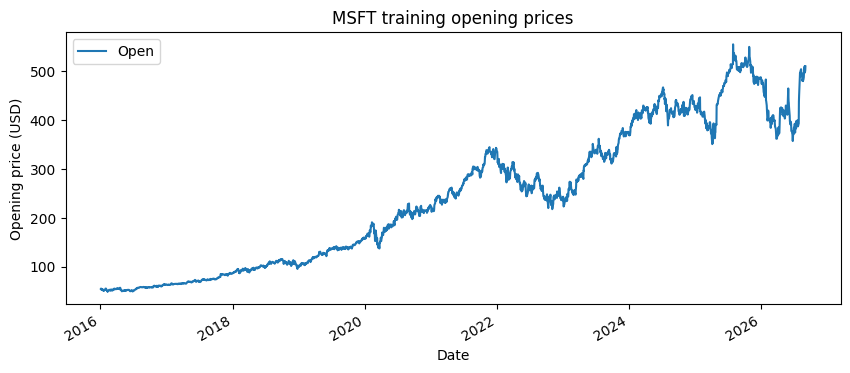

In [5]:
# Chart of the training prices, to see the overall trend and the price range.
msft_train.plot(x="Date", y="Open", figsize=(10, 4), title="MSFT training opening prices")
plt.ylabel("Opening price (USD)")
plt.show()

#### Step 3: Scale the prices and build the training windows
The scaler is fitted on the training prices only and maps them to [0, 1]; test prices above the training maximum would get values above 1.
For each target day *i*, the input window is days *i − 60* to *i − 1*. With *N* training days this gives *N − 60* examples, each of shape `(60, 1)`.

In [6]:
# STEP 3: rescale the prices to 0-1 and cut the training data into 60-day windows.
# Result: features_set (the inputs) with shape (2624, 60, 1) and labels (the answers)
# with shape (2624, 1). Each input is 60 days of prices; its answer is the 61st day.

# Take the Open column as an array with one row per day and one column.
# float32 is the number format PyTorch uses for its weights.
msft_train_open = msft_train[["Open"]].to_numpy(dtype=np.float32)
msft_test_open = msft_test[["Open"]].to_numpy(dtype=np.float32)
# Scale with x_scaled = (x - min) / (max - min): the lowest training price becomes 0 and
# the highest becomes 1. fit_transform learns min and max from the TRAINING prices only,
# so the model learns nothing about the test period.
scaler = MinMaxScaler(feature_range=(0, 1))
msft_train_scaled = scaler.fit_transform(msft_train_open).astype(np.float32)

# For each answer day i (starting at day 60), take the 60 days just before it
# (days i-60 ... i-1) as the input window, and stack all windows into one array.
features_set = np.stack([
    msft_train_scaled[i - LOOKBACK:i]
    for i in range(LOOKBACK, len(msft_train_scaled))
])
# The answer for each window is the price of the day right after it.
labels = msft_train_scaled[LOOKBACK:].copy()
print("Inputs:", features_set.shape)  # (windows, 60 days, 1 price per day)
print("Targets:", labels.shape)       # (windows, 1 answer)

Inputs: (2624, 60, 1)
Targets: (2624, 1)


#### Step 4: Mini-batches
`TensorDataset` pairs each window with its target and `DataLoader` serves them in shuffled mini-batches of 32. Shuffling whole windows
is fine, because the order of the days inside each window does not change.

In [7]:
# STEP 4: turn the arrays into PyTorch tensors and prepare them to be served in batches.
# A tensor is PyTorch's version of a NumPy array; it can be moved to the GPU.
# Result: train_loader, which gives 82 batches of up to 32 (window, answer) pairs per epoch.

X_train = torch.from_numpy(features_set).float()  # Inputs as a float32 tensor.
y_train = torch.from_numpy(labels).float()        # Answers as a float32 tensor.
train_dataset = TensorDataset(X_train, y_train)   # Keeps each window next to its answer.

# The DataLoader shuffles the windows each epoch (so the model doesn't see them in date
# order every time) and hands them out 32 at a time. Shuffling whole windows is fine: the
# order of the 60 days INSIDE each window never changes. The seeded generator makes the
# shuffle order the same in every run.
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=0,  # Prepare batches in the notebook itself (no helper processes needed).
)
print(f"{len(train_dataset)} examples in {len(train_loader)} batches per epoch")

2624 examples in 82 batches per epoch


#### Step 5: The RNN model
Each RNN layer updates its hidden state with $h_t = \tanh(W_{ih}x_t + b_{ih} + W_{hh}h_{t-1} + b_{hh})$, using the same weights at every
time step. The model has 4 RNN layers of 50 units with dropout after each; the output of the last layer at the last day (day 60) goes into
a linear layer that predicts the next day's price.

| Operation | Shape |
|---|---|
| Input batch | `(B, 60, 1)` |
| Output of each RNN layer | `(B, 60, 50)` |
| Last day of the 4th layer | `(B, 50)` |
| Linear output | `(B, 1)` |

In [8]:
# STEP 5: define the RNN model and create it.
# Data flows: 60 daily prices -> 4 stacked RNN layers -> the memory after day 60
# -> one Linear layer -> 1 number = the predicted (scaled) price for the next day.

class MsftRNN(nn.Module):
    # __init__ creates the layers (and their weights) once, when the model is built.
    def __init__(self, input_size=1, hidden_size=50, dropout=0.2):
        super().__init__()  # Required first line: lets PyTorch track the layers' weights.

        # An RNN layer reads the days one by one and updates a memory of 50 numbers each
        # day: new memory = tanh(weights x today's input + weights x yesterday's memory).
        # tanh keeps the memory between -1 and 1. batch_first=True means the data is
        # arranged as (windows in the batch, days, values per day).
        # Layer 1 reads 1 value per day (the price) ...
        self.rnn1 = nn.RNN(input_size, hidden_size, num_layers=1,
                           nonlinearity="tanh", batch_first=True)
        # ... and layers 2-4 each read the 50 memory values per day from the layer below,
        # which lets them pick up more complex patterns.
        self.rnn2 = nn.RNN(hidden_size, hidden_size, num_layers=1,
                           nonlinearity="tanh", batch_first=True)
        self.rnn3 = nn.RNN(hidden_size, hidden_size, num_layers=1,
                           nonlinearity="tanh", batch_first=True)
        self.rnn4 = nn.RNN(hidden_size, hidden_size, num_layers=1,
                           nonlinearity="tanh", batch_first=True)

        # Dropout after each layer: during training it hides 20% of the values at random,
        # so the model cannot rely on any single value (this reduces overfitting).
        # It is switched off automatically when making predictions.
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)
        self.dropout4 = nn.Dropout(dropout)
        # The output layer combines the 50 memory values into 1 predicted price.
        self.output = nn.Linear(hidden_size, 1)

    # forward describes how a batch of windows moves through the layers.
    # x arrives with shape (B, 60, 1): B windows, 60 days, 1 price per day.
    def forward(self, x):
        # Each RNN layer returns two things: its memory for every day (kept in x) and its
        # final memory (not needed, so it goes into "_"). The memory starts at zero for
        # every window, so windows don't affect each other.
        x, _ = self.rnn1(x)     # (B, 60, 1)  -> (B, 60, 50)
        x = self.dropout1(x)    # Hide 20% of the values (training only); shape unchanged.
        x, _ = self.rnn2(x)     # (B, 60, 50) -> (B, 60, 50); all 60 days go to the next layer.
        x = self.dropout2(x)    # Same dropout as above.
        x, _ = self.rnn3(x)     # (B, 60, 50) -> (B, 60, 50)
        x = self.dropout3(x)
        x, _ = self.rnn4(x)     # (B, 60, 50) -> (B, 60, 50)

        # Keep only the memory after the LAST day of each window. It summarises all 60 days
        # and is used to predict the next day. (B, 60, 50) -> (B, 50)
        x = x[:, -1, :]
        x = self.dropout4(x)
        # (B, 50) -> (B, 1): one predicted scaled price per window. There is no sigmoid at
        # the end, because future prices can be above the training maximum (scaled > 1).
        return self.output(x)


# Store the settings so the same model can be rebuilt when it is loaded from file (Step 9).
model_config = {"input_size": 1, "hidden_size": HIDDEN_SIZE, "dropout": DROPOUT}
model = MsftRNN(**model_config).to(device)  # Build the model and put it on the GPU.
print(model)  # List of the layers.
# Count the trainable weights (the numbers the model will learn).
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MsftRNN(
  (rnn1): RNN(1, 50, batch_first=True)
  (rnn2): RNN(50, 50, batch_first=True)
  (rnn3): RNN(50, 50, batch_first=True)
  (rnn4): RNN(50, 50, batch_first=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (dropout2): Dropout(p=0.2, inplace=False)
  (dropout3): Dropout(p=0.2, inplace=False)
  (dropout4): Dropout(p=0.2, inplace=False)
  (output): Linear(in_features=50, out_features=1, bias=True)
)
Trainable parameters: 18001


#### Step 6: Train the RNN
For every mini-batch: clear the old gradients, predict, compute the MSE loss, backpropagate through all 60 time steps
(backpropagation through time), clip the gradients, and update the weights with Adam.

In [9]:
# STEP 6: train the RNN. For each batch the model predicts, measures its error, works out
# how each weight should change, and changes it a little. This repeats for 100 epochs.
# Result: a trained model, and history["loss"] = the average error of each epoch.

# The error measure (loss): mean squared error = average of (prediction - answer)^2.
criterion = nn.MSELoss()
# Adam is the method that updates the weights; it adapts the step size for each weight.
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {"loss": []}  # Will hold one average error per epoch, for the chart below.

for epoch in range(EPOCHS):
    model.train()  # Training mode: dropout is active.
    total_squared_error = 0.0  # Sum of the errors in this epoch.
    examples_seen = 0          # Number of windows used so far in this epoch.

    for batch_x, batch_y in train_loader:  # Up to 32 windows and their answers at a time.
        # Move the batch to the GPU, where the model is.
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        # A gradient says, for one weight, in which direction and how strongly to change it
        # to lower the error. PyTorch adds new gradients to the old ones, so the previous
        # batch's gradients are cleared first.
        optimizer.zero_grad(set_to_none=True)
        # Run the batch through the model: one predicted price per window, shape (B, 1).
        batch_predictions = model(batch_x)
        # Safety check: predictions and answers must have the same shape, (B, 1).
        assert batch_predictions.shape == batch_y.shape
        loss = criterion(batch_predictions, batch_y)  # The average squared error of this batch.
        # Work backwards from the error through all 60 days to get every weight's gradient
        # ("backpropagation through time").
        loss.backward()
        # In an RNN the gradients can suddenly become huge ("exploding gradients"), which
        # would wreck the weights. If their combined size is above MAX_GRAD_NORM, shrink them.
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)
        optimizer.step()  # Change every weight a small step in the direction that lowers the error.

        # Add up the error of this batch (average x number of windows; the last batch is
        # smaller than 32, so it must not count as a full batch).
        batch_count = batch_x.size(0)
        total_squared_error += loss.item() * batch_count
        examples_seen += batch_count

    epoch_loss = total_squared_error / examples_seen  # Average error over the whole epoch.
    history["loss"].append(epoch_loss)
    # Print progress after the first epoch and then every 10 epochs.
    if epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == EPOCHS:
        print(f"Epoch {epoch + 1:3d}/{EPOCHS}: training MSE = {epoch_loss:.6f}")

Epoch   1/100: training MSE = 0.031957
Epoch  10/100: training MSE = 0.002407
Epoch  20/100: training MSE = 0.001537
Epoch  30/100: training MSE = 0.001428
Epoch  40/100: training MSE = 0.001213
Epoch  50/100: training MSE = 0.001116
Epoch  60/100: training MSE = 0.001020
Epoch  70/100: training MSE = 0.001212
Epoch  80/100: training MSE = 0.001145
Epoch  90/100: training MSE = 0.000978
Epoch 100/100: training MSE = 0.001084


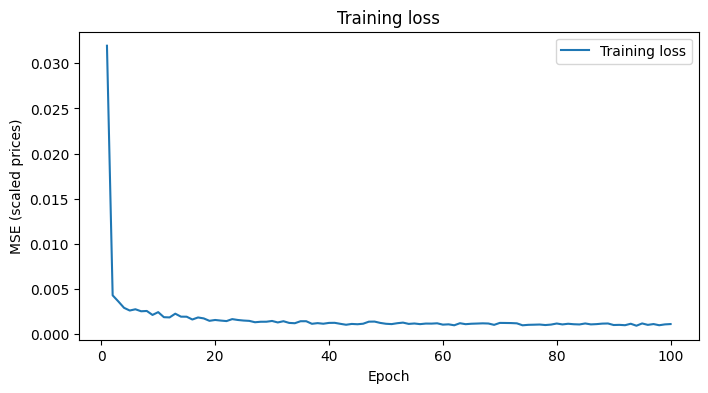

In [10]:
# Chart of the average training error per epoch. A falling curve means the model is
# learning the training data (it says nothing yet about the test period).
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(history["loss"]) + 1), history["loss"], label="Training loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled prices)")
plt.title("Training loss")
plt.legend()
plt.show()

#### Step 7: Test windows (rolling one-step-ahead prediction)
The first test day (Sep 9) needs the 60 trading days before it, which are the last 60 training days, so they are joined to the test prices.
Each test day then gets its own window of the 60 actual prices before it, scaled with the training scaler.

In [11]:
# STEP 7: build one 60-day input window for each test day.
# Result: X_test with shape (23, 60, 1) and test_loader, which serves them in date order.

# To predict the first test day (Sep 9), the model needs the 60 days before it, which are
# the last 60 training days. So put those in front of the test prices.
context_prices = np.concatenate([msft_train_open[-LOOKBACK:], msft_test_open], axis=0)
# Scale with the SAME min and max as the training data (transform only, no new fit).
context_scaled = scaler.transform(context_prices).astype(np.float32)
# Window i = the 60 actual prices just before test day i. It never includes day i itself,
# so the model never sees the price it is asked to predict.
test_features = np.stack([
    context_scaled[i:i + LOOKBACK]
    for i in range(len(msft_test_open))
])
X_test = torch.from_numpy(test_features).float()
# shuffle=False keeps the windows in date order.
test_loader = DataLoader(TensorDataset(X_test), batch_size=BATCH_SIZE, shuffle=False)
print("Test inputs:", X_test.shape)  # (test days, 60 days, 1 price)

Test inputs: torch.Size([23, 60, 1])


#### Step 8: Predict and compare with the baseline
`model.eval()` turns dropout off and `torch.inference_mode()` turns off gradient tracking. The predictions are converted back to dollars and
compared with the baseline "tomorrow's open = today's open" using MAE (average miss in dollars) and RMSE (like MAE, but large misses count more).

In [12]:
# STEP 8: predict every test day, convert back to dollars, and compare with the baseline.
# Result: predictions (in $), plus MAE and RMSE for the model and for the baseline.

model.eval()  # Prediction mode: dropout is switched off, so the full model is used.
prediction_batches = []
# inference_mode tells PyTorch no gradients are needed, which is faster and uses less memory.
with torch.inference_mode():
    for (batch_x,) in test_loader:
        batch_predictions = model(batch_x.to(device))
        # Move the predictions back from the GPU and turn them into a NumPy array.
        prediction_batches.append(batch_predictions.cpu().numpy())

scaled_predictions = np.concatenate(prediction_batches, axis=0)  # All test days in one array.
# Undo the 0-1 scaling to get prices in dollars.
predictions = scaler.inverse_transform(scaled_predictions)
assert predictions.shape == msft_test_open.shape  # One prediction per test day.

# Baseline: "today's opening price = yesterday's opening price". It needs no model at all,
# so the network is only useful if its error is lower than this.
baseline = context_prices[LOOKBACK - 1:-1]
# MAE = average size of the miss in $. RMSE = similar, but large misses count more.
for name, values in [("RNN", predictions), ("Previous-open baseline", baseline)]:
    errors = values - msft_test_open  # Miss on each test day (+ = too high, - = too low).
    print(f"{name}: MAE = ${np.abs(errors).mean():.2f}; RMSE = ${np.sqrt(np.mean(errors ** 2)):.2f}")

RNN: MAE = $14.61; RMSE = $16.48
Previous-open baseline: MAE = $4.96; RMSE = $6.39


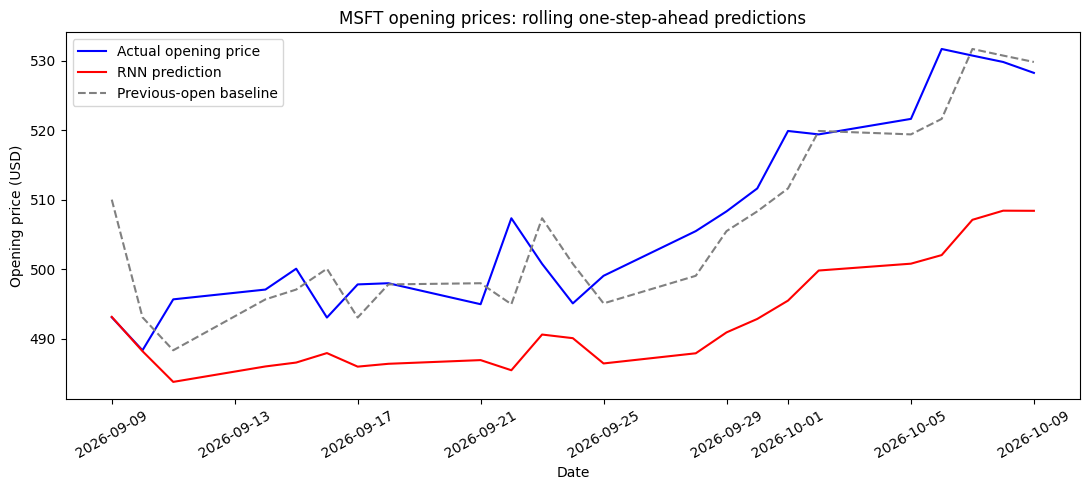

In [13]:
# Chart of the test period: actual opening prices (blue), the model's predictions (red)
# and the baseline (gray dashes).
plt.figure(figsize=(11, 5))
plt.plot(msft_test["Date"], msft_test_open[:, 0], color="blue", label="Actual opening price")
plt.plot(msft_test["Date"], predictions[:, 0], color="red", label="RNN prediction")
plt.plot(msft_test["Date"], baseline[:, 0], color="gray", linestyle="--", label="Previous-open baseline")
plt.title("MSFT opening prices: rolling one-step-ahead predictions")
plt.xlabel("Date")
plt.ylabel("Opening price (USD)")
plt.legend()
plt.xticks(rotation=30)  # Tilt the dates so they don't overlap.
plt.tight_layout()       # Fit everything inside the figure.
plt.show()

#### Step 9: Save the model
`torch.save` is the PyTorch version of Keras' `model.save('...')`. The file stores the weights, the model settings, the training history and
the scaler's values. The second cell loads the file back and checks that it gives the same predictions.

In [14]:
# STEP 9: save the trained RNN to a file (PyTorch's version of Keras' model.save).
# Result: output/msft_rnn_pytorch.pt

output_dir = Path(OUTPUT_DIR).expanduser()
checkpoint_path = output_dir / "msft_rnn_pytorch.pt"
# Everything stored in the file:
checkpoint = {
    # The learned weights. A "state_dict" is PyTorch's list of every layer's weights.
    # They are copied to the CPU so the file can be opened on a computer without a GPU.
    "model_state_dict": {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
    "model_config": model_config,      # Settings needed to rebuild the same model.
    "lookback": LOOKBACK,              # The model expects 60-day windows.
    "model_type": "vanilla_rnn_tanh",  # Label: which kind of model this is.
    "max_grad_norm": MAX_GRAD_NORM,    # Clipping limit used during training.
    "history": history,                # Training error of each epoch.
    # The scaler's learned values (training min, max, etc.). They are needed to turn
    # future predictions back into dollars with exactly the same scale.
    "scaler": {
        "feature_range": list(scaler.feature_range),
        "scale_": scaler.scale_.tolist(),
        "min_": scaler.min_.tolist(),
        "data_min_": scaler.data_min_.tolist(),
        "data_max_": scaler.data_max_.tolist(),
        "data_range_": scaler.data_range_.tolist(),
        "n_features_in_": int(scaler.n_features_in_),
        "n_samples_seen_": int(scaler.n_samples_seen_),
    },
}
output_dir.mkdir(parents=True, exist_ok=True)  # Create the output folder if it is missing.
torch.save(checkpoint, checkpoint_path)        # Write the file.
print("Saved:", checkpoint_path.resolve())

Saved: /content/output/msft_rnn_pytorch.pt


In [15]:
# Check that the saved file works: rebuild the model and the scaler from it and make sure
# they give exactly the same predictions as the model in memory.

# Read the file. weights_only=True only loads plain data (safer than loading any object).
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
# Build a new model with the same settings (it starts with random weights) ...
reloaded_model = MsftRNN(**saved["model_config"])
# ... and replace its weights with the saved ones.
reloaded_model.load_state_dict(saved["model_state_dict"])
reloaded_model = reloaded_model.to(device)
reloaded_model.eval()  # New models start in training mode, so switch dropout off.

# Rebuild the scaler by copying the saved min, max, etc. into an empty one.
reloaded_scaler = MinMaxScaler(feature_range=tuple(saved["scaler"]["feature_range"]))
for name in ("scale_", "min_", "data_min_", "data_max_", "data_range_"):
    setattr(reloaded_scaler, name, np.asarray(saved["scaler"][name], dtype=np.float32))
reloaded_scaler.n_features_in_ = saved["scaler"]["n_features_in_"]
reloaded_scaler.n_samples_seen_ = saved["scaler"]["n_samples_seen_"]

# Compare: both models get the same test windows; the outputs must match, otherwise
# assert_close stops with an error.
with torch.inference_mode():
    sample = X_test[:BATCH_SIZE].to(device)
    expected = model(sample)
    actual = reloaded_model(sample)
    torch.testing.assert_close(actual, expected)
# The rebuilt scaler must also turn the predictions into the same dollar values.
np.testing.assert_allclose(
    reloaded_scaler.inverse_transform(scaled_predictions), predictions
)
print("Reloaded model and scaler reproduce the original predictions.")

Reloaded model and scaler reproduce the original predictions.


### Part B: LSTM (class notebook `2_LSTM_apple_stock_prediction`)
Steps 1–4 of the LSTM notebook are the same code as in Part A, so the data, scaler, windows and test windows from Part A are reused.

#### Reset the random state
These are the seeding lines from Step 1 and the `DataLoader` from Step 4, run again so the LSTM starts from the same random state as in its own notebook.

In [16]:
# Reset the randomness before building the LSTM (the same lines as in Steps 1 and 4).
# Training the RNN used up random numbers, so without this the LSTM would start from a
# different random state than when its class notebook is run on its own.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# A new DataLoader with a freshly seeded generator, so the batches are shuffled in the
# same order as in the class LSTM notebook.
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=0,
)
print(f"{len(train_dataset)} examples in {len(train_loader)} batches per epoch")

2624 examples in 82 batches per epoch


#### Step 5: The LSTM model
Same structure as the RNN, with `nn.LSTM` layers instead of `nn.RNN`. Each LSTM layer also keeps a cell state and uses gates to decide what to
forget, store and output (see Appendix A.6). `nn.LSTM` returns `(outputs, (h_n, c_n))`; only the outputs are used.

In [17]:
# STEP 5 (LSTM): the same structure as the RNN in Part A, but with LSTM layers.
# An LSTM layer keeps two memories: a short-term one (the output, as in the RNN) and a
# long-term "cell state". Three gates decide what to forget, what to store and what to
# output, which helps it remember information from further back (see Appendix A.6).

class MsftLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, dropout=0.2):
        super().__init__()  # Required first line: lets PyTorch track the layers' weights.
        # Layer 1 reads 1 value per day (the price); layers 2-4 read the 50 values per day
        # from the layer below.
        self.lstm1 = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.lstm2 = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        self.lstm3 = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        self.lstm4 = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        # Dropout after each layer, as in the RNN (hides 20% of values during training).
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)
        self.dropout4 = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, 1)  # 50 memory values -> 1 predicted price.

    def forward(self, x):
        # x: (B, 60, 1). An LSTM layer returns its output for every day plus a pair of final
        # memories (short-term, long-term); only the outputs are kept, the pair goes into "_".
        x, _ = self.lstm1(x)  # (B, 60, 1)  -> (B, 60, 50)
        x = self.dropout1(x)
        x, _ = self.lstm2(x)  # (B, 60, 50) -> (B, 60, 50)
        x = self.dropout2(x)
        x, _ = self.lstm3(x)  # (B, 60, 50) -> (B, 60, 50)
        x = self.dropout3(x)
        x, _ = self.lstm4(x)  # (B, 60, 50) -> (B, 60, 50)

        # Keep the output after the last day, which summarises the window: (B, 60, 50) -> (B, 50)
        x = x[:, -1, :]
        x = self.dropout4(x)
        # (B, 50) -> (B, 1): the predicted scaled price for the next day.
        return self.output(x)


model_config = {"input_size": 1, "hidden_size": HIDDEN_SIZE, "dropout": DROPOUT}  # Same as RNN.
model = MsftLSTM(**model_config).to(device)  # Build the LSTM and put it on the GPU.
print(model)
# The LSTM has about 4 times more weights than the RNN, because each gate has its own weights.
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MsftLSTM(
  (lstm1): LSTM(1, 50, batch_first=True)
  (lstm2): LSTM(50, 50, batch_first=True)
  (lstm3): LSTM(50, 50, batch_first=True)
  (lstm4): LSTM(50, 50, batch_first=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (dropout2): Dropout(p=0.2, inplace=False)
  (dropout3): Dropout(p=0.2, inplace=False)
  (dropout4): Dropout(p=0.2, inplace=False)
  (output): Linear(in_features=50, out_features=1, bias=True)
)
Trainable parameters: 71851


#### Step 6: Train the LSTM
The same training loop as in Part A, without gradient clipping (as in the class LSTM notebook).

In [18]:
# STEP 6 (LSTM): the same training loop as in Part A, except that there is no gradient
# clipping (the class LSTM notebook does not clip; LSTMs are less prone to huge gradients).

criterion = nn.MSELoss()  # Error measure: mean squared error.
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)  # Updates the weights.
history = {"loss": []}  # Average error of each epoch.

for epoch in range(EPOCHS):
    model.train()  # Training mode: dropout active.
    total_squared_error = 0.0
    examples_seen = 0

    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)  # Move the batch to the GPU.
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)  # Clear the previous batch's gradients.
        batch_predictions = model(batch_x)     # Predict one price per window.
        assert batch_predictions.shape == batch_y.shape
        loss = criterion(batch_predictions, batch_y)  # Error of this batch.
        loss.backward()   # Gradient of every weight (backpropagation through time).
        optimizer.step()  # Change the weights a small step to lower the error.

        # Add up the error of this batch, weighted by its size.
        batch_count = batch_x.size(0)
        total_squared_error += loss.item() * batch_count
        examples_seen += batch_count

    epoch_loss = total_squared_error / examples_seen  # Average error over the epoch.
    history["loss"].append(epoch_loss)
    if epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == EPOCHS:  # Print every 10 epochs.
        print(f"Epoch {epoch + 1:3d}/{EPOCHS}: training MSE = {epoch_loss:.6f}")

Epoch   1/100: training MSE = 0.051825
Epoch  10/100: training MSE = 0.002060
Epoch  20/100: training MSE = 0.001369
Epoch  30/100: training MSE = 0.001218
Epoch  40/100: training MSE = 0.001016
Epoch  50/100: training MSE = 0.000915
Epoch  60/100: training MSE = 0.000881
Epoch  70/100: training MSE = 0.000839
Epoch  80/100: training MSE = 0.000810
Epoch  90/100: training MSE = 0.000716
Epoch 100/100: training MSE = 0.000775


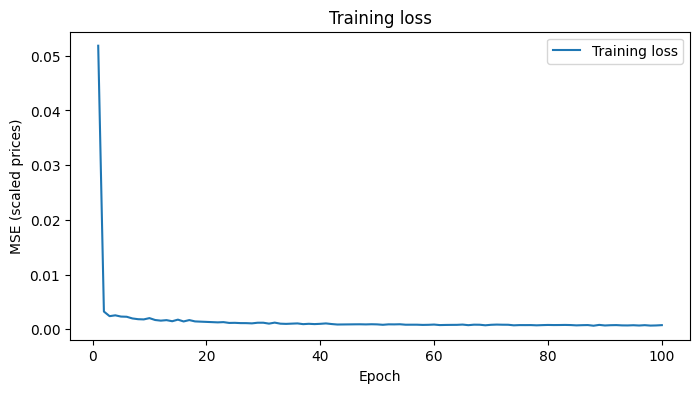

In [19]:
# Chart of the average training error per epoch. A falling curve means the model is
# learning the training data (it says nothing yet about the test period).
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(history["loss"]) + 1), history["loss"], label="Training loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled prices)")
plt.title("Training loss")
plt.legend()
plt.show()

#### Step 8: Predict and compare with the baseline
The test windows from Part A (Step 7) are used.

In [20]:
# STEP 8: predict every test day, convert back to dollars, and compare with the baseline.
# Result: predictions (in $), plus MAE and RMSE for the model and for the baseline.

model.eval()  # Prediction mode: dropout is switched off, so the full model is used.
prediction_batches = []
# inference_mode tells PyTorch no gradients are needed, which is faster and uses less memory.
with torch.inference_mode():
    for (batch_x,) in test_loader:
        batch_predictions = model(batch_x.to(device))
        # Move the predictions back from the GPU and turn them into a NumPy array.
        prediction_batches.append(batch_predictions.cpu().numpy())

scaled_predictions = np.concatenate(prediction_batches, axis=0)  # All test days in one array.
# Undo the 0-1 scaling to get prices in dollars.
predictions = scaler.inverse_transform(scaled_predictions)
assert predictions.shape == msft_test_open.shape  # One prediction per test day.

# Baseline: "today's opening price = yesterday's opening price". It needs no model at all,
# so the network is only useful if its error is lower than this.
baseline = context_prices[LOOKBACK - 1:-1]
# MAE = average size of the miss in $. RMSE = similar, but large misses count more.
for name, values in [("LSTM", predictions), ("Previous-open baseline", baseline)]:
    errors = values - msft_test_open  # Miss on each test day (+ = too high, - = too low).
    print(f"{name}: MAE = ${np.abs(errors).mean():.2f}; RMSE = ${np.sqrt(np.mean(errors ** 2)):.2f}")

LSTM: MAE = $19.46; RMSE = $20.64
Previous-open baseline: MAE = $4.96; RMSE = $6.39


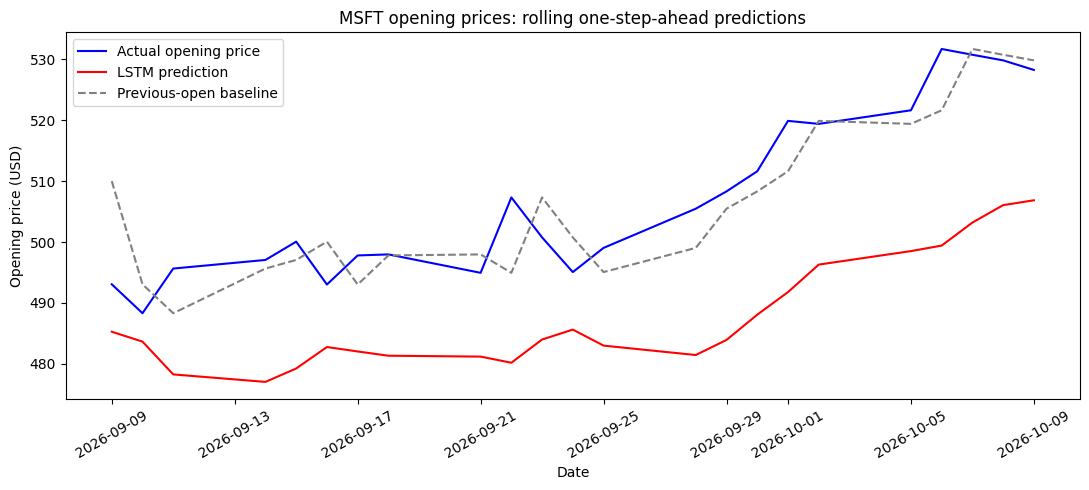

In [21]:
# Chart of the test period: actual opening prices (blue), the model's predictions (red)
# and the baseline (gray dashes).
plt.figure(figsize=(11, 5))
plt.plot(msft_test["Date"], msft_test_open[:, 0], color="blue", label="Actual opening price")
plt.plot(msft_test["Date"], predictions[:, 0], color="red", label="LSTM prediction")
plt.plot(msft_test["Date"], baseline[:, 0], color="gray", linestyle="--", label="Previous-open baseline")
plt.title("MSFT opening prices: rolling one-step-ahead predictions")
plt.xlabel("Date")
plt.ylabel("Opening price (USD)")
plt.legend()
plt.xticks(rotation=30)  # Tilt the dates so they don't overlap.
plt.tight_layout()       # Fit everything inside the figure.
plt.show()

#### Step 9: Save the model

In [22]:
# STEP 9 (LSTM): save the trained LSTM to a file, as for the RNN.
# Result: output/msft_lstm_pytorch.pt

checkpoint_path = OUTPUT_DIR / "msft_lstm_pytorch.pt"
# Everything stored in the file:
checkpoint = {
    # The learned weights, copied to the CPU so the file opens on any computer.
    "model_state_dict": {key: value.detach().cpu().clone() for key, value in model.state_dict().items()},
    "model_config": model_config,  # Settings needed to rebuild the same model.
    "lookback": LOOKBACK,          # The model expects 60-day windows.
    "history": history,            # Training error of each epoch.
    # The scaler's learned values (training min, max, etc.). They are needed to turn
    # future predictions back into dollars with exactly the same scale.
    "scaler": {
        "feature_range": list(scaler.feature_range),
        "scale_": scaler.scale_.tolist(),
        "min_": scaler.min_.tolist(),
        "data_min_": scaler.data_min_.tolist(),
        "data_max_": scaler.data_max_.tolist(),
        "data_range_": scaler.data_range_.tolist(),
        "n_features_in_": int(scaler.n_features_in_),
        "n_samples_seen_": int(scaler.n_samples_seen_),
    },
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # Create the output folder if it is missing.
torch.save(checkpoint, checkpoint_path)        # Write the file.
print("Saved:", checkpoint_path.resolve())

Saved: /content/output/msft_lstm_pytorch.pt


In [23]:
# Check that the saved file works: rebuild the model and the scaler from it and make sure
# they give exactly the same predictions as the model in memory.

# Read the file. weights_only=True only loads plain data (safer than loading any object).
saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
# Build a new model with the same settings (it starts with random weights) ...
reloaded_model = MsftLSTM(**saved["model_config"])
# ... and replace its weights with the saved ones.
reloaded_model.load_state_dict(saved["model_state_dict"])
reloaded_model = reloaded_model.to(device)
reloaded_model.eval()  # New models start in training mode, so switch dropout off.

# Rebuild the scaler by copying the saved min, max, etc. into an empty one.
reloaded_scaler = MinMaxScaler(feature_range=tuple(saved["scaler"]["feature_range"]))
for name in ("scale_", "min_", "data_min_", "data_max_", "data_range_"):
    setattr(reloaded_scaler, name, np.asarray(saved["scaler"][name], dtype=np.float32))
reloaded_scaler.n_features_in_ = saved["scaler"]["n_features_in_"]
reloaded_scaler.n_samples_seen_ = saved["scaler"]["n_samples_seen_"]

# Compare: both models get the same test windows; the outputs must match, otherwise
# assert_close stops with an error.
with torch.inference_mode():
    sample = X_test[:BATCH_SIZE].to(device)
    expected = model(sample)
    actual = reloaded_model(sample)
    torch.testing.assert_close(actual, expected)
# The rebuilt scaler must also turn the predictions into the same dollar values.
np.testing.assert_allclose(
    reloaded_scaler.inverse_transform(scaled_predictions), predictions
)
print("Reloaded model and scaler reproduce the original predictions.")

Reloaded model and scaler reproduce the original predictions.


## Results and discussion
The numbers below are from my Colab run (T4 GPU). GPU calculations are not exactly repeatable, so re-running the notebook changes
the model results slightly (by about a cent). That is why the model numbers below are rounded; the exact values are in the outputs
of Part A and Part B. The baseline does not use a model, so its numbers are exact.

#### Results
2,684 training days (Jan 4, 2016 – Sep 4, 2026), 2,624 training windows of 60 days, and 23 test days (Sep 9 – Oct 9, 2026).

| Method | Training MSE after 100 epochs (scaled prices) | Test MAE | Test RMSE | Better than the baseline? |
|---|---|---|---|---|
| RNN (Part A) | ≈ 0.0011 | **≈ \$14.6** | ≈ \$16.5 | No |
| LSTM (Part B) | ≈ 0.0008 | **≈ \$19.5** | ≈ \$20.6 | No |
| Baseline (previous open) | – | **\$4.96** | \$6.39 | – |

#### Discussion
1. Both models learned the training data. The training error fell from 0.032 (RNN) and 0.052 (LSTM) in the first epoch to about
   0.002 by epoch 10 and then leveled off. After 100 epochs the LSTM's training error was about 30% lower than the RNN's
   (about 0.0008 vs 0.0011).
2. On the test period both models predicted too low. MSFT opened at about \$493 on Sep 9 and about \$528 on Oct 9 (+7%), and in both
   charts the predicted line stays below the actual line. The RNN is almost exactly right on Sep 9 and Sep 10 and then falls behind;
   the LSTM is below the actual price from the first day (by about \$8 on Sep 9). For both models the gap is largest around Oct 6,
   at about \$30.
3. The predictions lag the actual price. The predicted lines are much smoother than the actual price, and they only start to rise
   after the price has already moved up at the end of September. My guess is that the 60-day windows still contained the lower
   summer 2026 prices (the training chart shows a dip to roughly \$360–\$400 and a jump to about \$510 just before the test period),
   which pulls the predictions down while the price is rising. The test prices (\$488–\$532) are inside the training range, which
   peaked at about \$550 in 2025, so this is not caused by prices the model had never seen.
4. The baseline was clearly better. "Tomorrow's open = today's open" missed by \$4.96 on average, about a third of the RNN's error
   and a quarter of the LSTM's. This is even though its Sep 9 guess had to use the Sep 4 open (Sep 8 is not in the data), which was
   about \$17 too high.
5. The RNN beat the LSTM on the test days (MAE about \$14.6 vs \$19.5), even though the LSTM had the lower training error. In the charts
   the LSTM line sits a few dollars below the RNN line on most days. So a lower training error did not carry over to new data.
   In the class Apple example it was the other way round (LSTM \$4.00 vs RNN \$7.88, baseline \$2.34), so which model does better
   seems to depend on the stock and the period; with only 23 test days, the difference between the two is not very reliable.

#### Conclusion
The class code worked on Microsoft data with small changes (downloading the data with `yfinance` and renaming Apple to MSFT).
Both networks learned the training data, and their predictions followed the general upward trend of the opening price during the
test period. But they lagged behind the price and were almost always too low, missing by about \$14.6 (RNN) and \$19.5 (LSTM) on average,
which is 3 to 4 times worse than simply using yesterday's opening price. With only past opening prices as input, neither model is
useful for forecasting.

Ideas for improvement:
* predict the daily change (or % return) instead of the price level, which should help with the lag and the downward offset;
* use a shorter window, or give more weight to recent days;
* add more inputs (close, high, low, volume, a market index);
* keep the last part of the training period as a validation set for tuning and early stopping.

# Problem 2: validation split, lookback windows and a five-day target
Starting from Problem 1, for both the RNN and the LSTM:

a) split the original training period in time order into 80% training and 20% validation, and fit the scaler on the training part only;
b) try lookback windows of 10, 30, 60 and 120 trading days;
c) change the data so that each input has shape (60, 1) and each target contains the five next opening prices.

## Approach
I reuse as much of Problem 1 as possible: the MSFT prices that were already downloaded (`msft_train`, `msft_test`), the two model
classes `MsftRNN` and `MsftLSTM`, the settings (50 units, dropout 0.2, batch size 32, 100 epochs, Adam, learning rate 0.001) and the
training loop (with gradient clipping for the RNN only, as in the class notebooks). Because Problem 2 needs 10 trained models,
the Problem 1 steps are put into a few small functions instead of being copied 10 times.

**(a) Validation split.** The days are not shuffled: the oldest 80% of Jan 2016 – Sep 4, 2026 is used for training and the newest
20% for validation. The scaler learns its min and max from the training part only, so the model learns nothing from the
validation days. The validation error is measured after every epoch, and the validation MAE is used to compare the settings.
The test period (Sep 9 – Oct 9, 2026) stays exactly as in Problem 1 and is only used at the end.

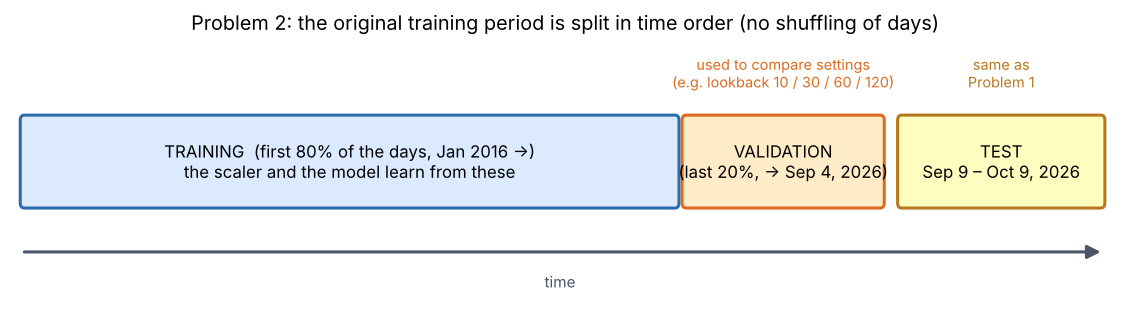

**(b) Lookback windows.** The same window code as in Problem 1, with the window length as a setting: 10, 30, 60 or 120 days
(about 2 weeks, 6 weeks, 3 months and 6 months). 2 models × 4 lookbacks = 8 trained models.

**(c) Five future prices.** Each input is still 60 days, but each target is now the next 5 opening prices instead of 1.
The model only needs one change: its last layer outputs 5 numbers instead of 1. The error is reported separately for 1, 2, …, 5
days ahead, and compared with the baseline "all 5 future prices = the last known price".

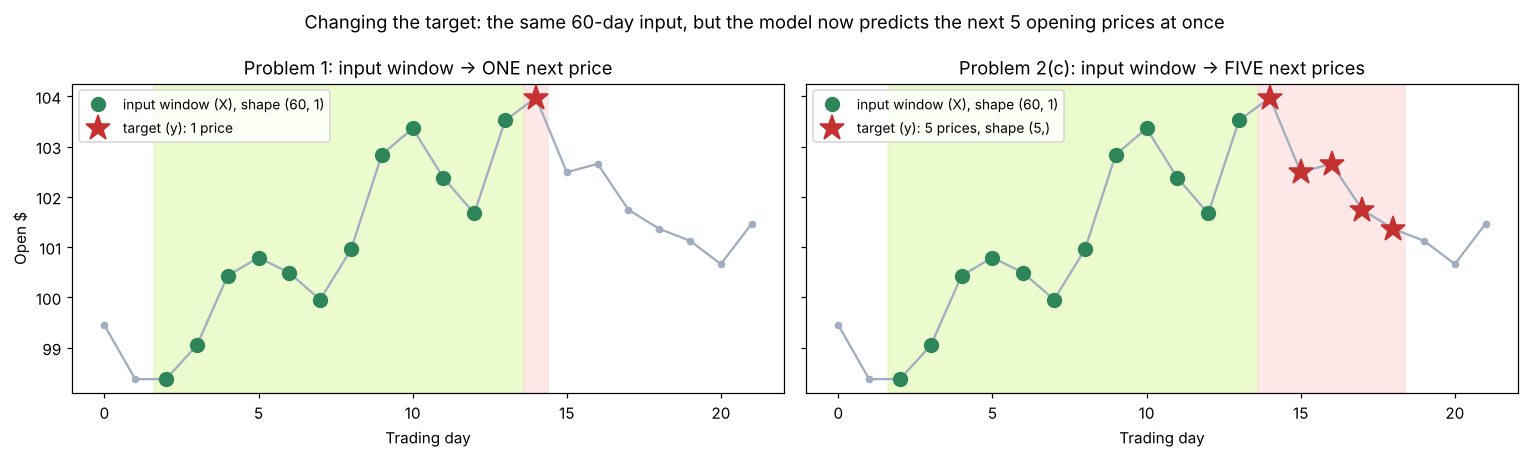

## Solution
### Step 1: Split the training period 80/20 and fit the scaler on the training part

In [ ]:
# PROBLEM 2(a): split the original training period (Jan 4, 2016 - Sep 4, 2026) in time order:
# the oldest 80% of the days are used for training and the newest 20% for validation.
# The days are NOT shuffled, so the model never trains on days that come after the validation days.
# The scaler is fitted on the training part only, so it learns nothing from the validation days.
# Uses from Problem 1: msft_train / msft_train_open (all training-period prices) and msft_test_open.
# Result: p2_train_open, p2_valid_open (prices in $) and scaler_p2.

split_index = int(0.8 * len(msft_train_open))  # Number of days in the training part (80%).
p2_train_open = msft_train_open[:split_index]   # Oldest 80% of the days: training.
p2_valid_open = msft_train_open[split_index:]   # Newest 20% of the days: validation.
train_dates = msft_train["Date"].iloc[:split_index]  # Dates of the training part (for printing).
valid_dates = msft_train["Date"].iloc[split_index:]  # Dates of the validation part.
# Show the size and the date range of each part.
print(f"Training:   {len(p2_train_open)} days, "
      f"{train_dates.min().date()} to {train_dates.max().date()}")
print(f"Validation: {len(p2_valid_open)} days, "
      f"{valid_dates.min().date()} to {valid_dates.max().date()}")
print(f"Test:       {len(msft_test_open)} days (same as Problem 1)")  # Test size.

scaler_p2 = MinMaxScaler(feature_range=(0, 1))  # A new scaler for Problem 2 ...
scaler_p2.fit(p2_train_open)  # ... that learns min and max from the TRAINING part only.
print(f"Training price range: ${p2_train_open.min():.2f} to ${p2_train_open.max():.2f}")
# Validation prices above the training maximum are scaled to values above 1 (that is allowed).
valid_scaled = scaler_p2.transform(p2_valid_open)  # Validation prices on the training scale.
print(f"Validation prices after scaling: {valid_scaled.min():.2f} to {valid_scaled.max():.2f}")

### Step 2: Windows with an adjustable lookback and horizon
`make_windows` is the Problem 1 window code with two settings: `lookback` (days in each input) and `horizon` (future prices in
each target). With lookback 60 and horizon 1 it builds exactly the Problem 1 windows.

In [ ]:
# Builds input windows and targets. This is the window code from Problem 1 (Steps 3 and 7) with two
# settings that can now be changed:
#   lookback = how many past days are in each input window (Problem 1 always used 60),
#   horizon  = how many future prices each target contains (Problem 1 always used 1).
def make_windows(prices, lookback, horizon):
    # Every day i that has `lookback` days before it and `horizon` days from it onward.
    positions = range(lookback, len(prices) - horizon + 1)
    inputs = np.stack([prices[i - lookback:i] for i in positions])     # Days i-lookback ... i-1.
    targets = np.stack([prices[i:i + horizon, 0] for i in positions])  # Days i ... i+horizon-1.
    return inputs, targets  # Shapes: (windows, lookback, 1) and (windows, horizon).


# Builds the training, validation and test windows for one (lookback, horizon) setting.
# Windows are cut twice: once from scaled prices (for the model) and once from prices in dollars
# (for the errors in $ and for the baseline).
def build_datasets(lookback, horizon):
    # Validation windows need the `lookback` days before the first validation day; they come from
    # the end of the training part. Their targets are always validation days.
    valid_context = np.concatenate([p2_train_open[-lookback:], p2_valid_open], axis=0)
    # Test windows need the `lookback` days before Sep 9, 2026: the end of the full training
    # period (as in Problem 1, Step 7). Their targets are always test days.
    test_context = np.concatenate([msft_train_open[-lookback:], msft_test_open], axis=0)
    data = {}  # Will hold the windows of each split.
    splits = [("train", p2_train_open), ("valid", valid_context), ("test", test_context)]  # 3 sets.
    for name, prices in splits:  # Training, validation and test, one after the other.
        scaled = scaler_p2.transform(prices).astype(np.float32)  # Scale with the training scaler.
        X, y = make_windows(scaled, lookback, horizon)            # Scaled windows for the model.
        X_dollars, y_dollars = make_windows(prices, lookback, horizon)  # Same windows in $.
        data[name] = {  # Everything about this split:
            "X": torch.from_numpy(X).float(),  # Model inputs as a tensor: (windows, lookback, 1).
            "y": torch.from_numpy(y).float(),  # Model targets as a tensor: (windows, horizon).
            "y_dollars": y_dollars,            # True future prices in $.
            # Baseline: every future day = the last price in the window (yesterday's open).
            "baseline": np.repeat(X_dollars[:, -1, :], horizon, axis=1),
        }
    return data  # data["train"], data["valid"], data["test"].


# Quick check with the Problem 1 setting (lookback 60, one future price).
example = build_datasets(lookback=60, horizon=1)
for name, split in example.items():  # Print the shapes of each split.
    print(f"{name:5s}: inputs {tuple(split['X'].shape)}, targets {tuple(split['y'].shape)}")

### Step 3: Training and evaluation functions
`train_p2` is the Problem 1 training loop plus the validation error after each epoch. `run_experiment` trains one model for one
setting, measures the validation and test MAE in dollars, and saves the trained weights.

In [ ]:
# Training and evaluation for one experiment. The training loop is the one from Problem 1 (Step 6);
# the only additions are the validation error after every epoch and a switch for gradient clipping
# (the RNN uses it, the LSTM does not, as in the two class notebooks).
import time  # Used to time each experiment.


def train_p2(model, train_loader, X_valid, y_valid, max_grad_norm):  # 100 epochs of training.
    criterion = nn.MSELoss()  # Error measure: mean squared error, as in Problem 1.
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)  # Adam, as in Problem 1.
    history = {"loss": [], "val_loss": []}  # Training and validation error of each epoch.
    for epoch in range(EPOCHS):  # 100 epochs, as in Problem 1.
        model.train()  # Training mode: dropout on.
        total_squared_error = 0.0  # Sum of the errors in this epoch.
        examples_seen = 0          # Number of windows used so far in this epoch.
        for batch_x, batch_y in train_loader:  # Batches of up to 32 windows.
            batch_x = batch_x.to(device)  # Move the inputs to the GPU ...
            batch_y = batch_y.to(device)  # ... and the targets too.
            optimizer.zero_grad(set_to_none=True)  # Clear the previous batch's gradients.
            batch_predictions = model(batch_x)     # Predict: shape (B, horizon).
            assert batch_predictions.shape == batch_y.shape  # Same shape as the targets.
            loss = criterion(batch_predictions, batch_y)  # Error of this batch.
            loss.backward()  # Gradients (backpropagation through time).
            if max_grad_norm is not None:  # RNN only: shrink gradients that are too large.
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)  # Limit size.
            optimizer.step()  # Update the weights.
            batch_count = batch_x.size(0)  # Windows in this batch.
            total_squared_error += loss.item() * batch_count  # Total error of the batch.
            examples_seen += batch_count  # Count the windows.
        history["loss"].append(total_squared_error / examples_seen)  # Average training error.
        # Validation error: the model predicts all validation windows (no training on them).
        model.eval()  # Dropout off.
        with torch.inference_mode():  # No gradients needed.
            valid_predictions = model(X_valid.to(device))  # Predict every validation window.
            valid_loss = criterion(valid_predictions, y_valid.to(device)).item()  # Their MSE.
        history["val_loss"].append(valid_loss)  # Keep it for the chart.
    return history  # Training and validation error per epoch.


def predict_dollars(model, X):  # Model predictions, in $.
    # Predicts all windows in X and converts the predictions from the 0-1 scale back to dollars.
    model.eval()  # Dropout off.
    with torch.inference_mode():  # No gradients needed.
        scaled = model(X.to(device)).cpu().numpy()  # Shape (windows, horizon), scaled.
    # The scaler works on one column: flatten, convert to $, and restore the shape.
    return scaler_p2.inverse_transform(scaled.reshape(-1, 1)).reshape(scaled.shape)


def mae(predictions, actual):  # Average absolute miss.
    return float(np.abs(predictions - actual).mean())  # Mean absolute error in $.


def run_experiment(model_class, lookback, horizon=1):  # One complete experiment.
    # Trains one model (MsftRNN or MsftLSTM from Problem 1) for one setting and measures its errors.
    started = time.perf_counter()  # Start a timer.
    # Reset the random generators (Problem 1, Step 1), so every experiment starts the same way.
    random.seed(SEED)                     # Python's generator.
    np.random.seed(SEED)                  # NumPy's generator.
    torch.manual_seed(SEED)               # PyTorch's generator (initial weights, dropout).
    if torch.cuda.is_available():         # On a GPU ...
        torch.cuda.manual_seed_all(SEED)  # ... seed the GPU's generator too.
    data = build_datasets(lookback, horizon)  # Windows for this setting.
    # Shuffled training batches with a seeded generator (Problem 1, Step 4).
    loader_generator = torch.Generator().manual_seed(SEED)
    train_set = TensorDataset(data["train"]["X"], data["train"]["y"])  # Pair windows with targets.
    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                              generator=loader_generator, num_workers=0)  # Same as Problem 1.
    model = model_class(**model_config)  # The Problem 1 model, unchanged.
    if horizon != 1:  # For 5 future prices, the last layer must output 5 numbers instead of 1.
        model.output = nn.Linear(HIDDEN_SIZE, horizon)  # New last layer: 50 -> 5.
    model = model.to(device)  # Put the model on the GPU.
    # Gradient clipping for the RNN only (as in the class RNN notebook).
    max_grad_norm = MAX_GRAD_NORM if model_class is MsftRNN else None
    history = train_p2(model, train_loader, data["valid"]["X"], data["valid"]["y"],
                       max_grad_norm)  # Train for 100 epochs.
    name = model_class.__name__.replace("Msft", "")  # "RNN" or "LSTM".
    result = {"model": name, "lookback": lookback, "horizon": horizon,
              "history": history}  # Everything about this experiment is collected here.
    for split in ("valid", "test"):  # Errors in $ on the validation and test windows.
        predictions = predict_dollars(model, data[split]["X"])  # Predicted prices in $.
        actual = data[split]["y_dollars"]   # True prices in $.
        baseline = data[split]["baseline"]  # Baseline prices in $.
        result[f"{split}_predictions"] = predictions  # Keep them for the tables and charts.
        result[f"{split}_actual"] = actual  # True prices.
        result[f"{split}_baseline"] = baseline  # Baseline prices.
        result[f"{split}_mae"] = mae(predictions, actual)        # Model error.
        result[f"{split}_baseline_mae"] = mae(baseline, actual)  # Baseline error.
    # Save the trained weights right after training (as the assignment asks).
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # Create the folder if needed.
    file_name = f"p2_{name.lower()}_lookback{lookback}_horizon{horizon}.pt"  # File name.
    torch.save(model.state_dict(), OUTPUT_DIR / file_name)  # Write the weights to the file.
    seconds = time.perf_counter() - started  # How long the experiment took.
    print(f"{name:4s} lookback {lookback:3d}, horizon {horizon}: "
          f"valid MAE ${result['valid_mae']:.2f}, test MAE ${result['test_mae']:.2f} "
          f"({seconds:.0f} s)")  # One line per experiment.
    return result  # Errors, predictions and training history.

### Step 4 (a, b): Train the RNN and the LSTM with lookbacks of 10, 30, 60 and 120 days
This trains 8 models, so this cell is the slowest part of Problem 2 (several minutes on a Colab T4 GPU).

In [ ]:
# PROBLEM 2(a) + (b): train the RNN and the LSTM with lookback windows of 10, 30, 60 and 120 days
# (one future price, as in Problem 1). That is 8 models, so this cell takes a while on the GPU.
LOOKBACKS = [10, 30, 60, 120]  # The window lengths to try.
lookback_results = []  # One result per (model, lookback).
for model_class in (MsftRNN, MsftLSTM):  # First all RNNs, then all LSTMs.
    for lookback in LOOKBACKS:  # Each window length.
        lookback_results.append(run_experiment(model_class, lookback))  # Train and evaluate.

In [ ]:
# Results table: one row per model and lookback, errors in $ (lower is better).
lookback_table = pd.DataFrame([{
    "Model": r["model"],                              # RNN or LSTM.
    "Lookback": r["lookback"],                        # Days per input window.
    "Final train MSE": r["history"]["loss"][-1],      # Training error (scaled prices).
    "Final valid MSE": r["history"]["val_loss"][-1],  # Validation error (scaled prices).
    "Valid MAE ($)": r["valid_mae"],                  # Average validation miss in $.
    "Test MAE ($)": r["test_mae"],                    # Average test miss in $.
} for r in lookback_results])
display(lookback_table.round({"Final train MSE": 6, "Final valid MSE": 6,
                              "Valid MAE ($)": 2, "Test MAE ($)": 2}))  # Show the table.
# The baseline is the same for every model and lookback: all settings predict the same validation
# days and the same test days (only the number of TRAINING windows changes with the lookback).
base = lookback_results[0]
print(f"Baseline (previous open): valid MAE ${base['valid_baseline_mae']:.2f}, "
      f"test MAE ${base['test_baseline_mae']:.2f}")
for name in ("RNN", "LSTM"):  # The lookback with the lowest validation error, for each model.
    rows = lookback_table[lookback_table["Model"] == name]  # This model's 4 rows.
    best = rows.loc[rows["Valid MAE ($)"].idxmin()]         # The row with the lowest valid MAE.
    print(f"Best {name} lookback on validation: {int(best['Lookback'])} days "
          f"(valid MAE ${best['Valid MAE ($)']:.2f})")

In [ ]:
# Left: validation MAE for each lookback. Right: validation error per epoch for the LSTM.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))  # Two charts side by side.
for name, color in (("RNN", "tab:red"), ("LSTM", "tab:green")):  # One line per model.
    rows = lookback_table[lookback_table["Model"] == name]  # This model's rows.
    axes[0].plot(rows["Lookback"], rows["Valid MAE ($)"], marker="o", color=color, label=name)
axes[0].axhline(base["valid_baseline_mae"], color="gray", linestyle="--",
                label="Previous-open baseline")  # Horizontal line for the baseline.
axes[0].set_xticks(LOOKBACKS)  # Ticks only at the tried lookbacks.
axes[0].set(title="Validation MAE by lookback window", xlabel="Lookback (trading days)",
            ylabel="MAE ($)")  # Titles and axis labels.
axes[0].legend()  # Show which line is which.
for r in lookback_results:  # One validation curve per LSTM lookback.
    if r["model"] == "LSTM":  # LSTM runs only.
        axes[1].plot(range(1, EPOCHS + 1), r["history"]["val_loss"],
                     label=f"lookback {r['lookback']}")
axes[1].set_yscale("log")  # The errors span a wide range.
axes[1].set(title="LSTM validation error during training", xlabel="Epoch",
            ylabel="Validation MSE (scaled)")  # Titles and axis labels.
axes[1].legend()  # Show which line is which.
fig.tight_layout()  # Fit everything inside the figure.
plt.show()  # Draw the charts.

### Step 5 (c): Each input has shape (60, 1) and each target contains five future opening prices

In [ ]:
# PROBLEM 2(c): each input still has shape (60, 1), but each target now contains the FIVE next
# opening prices. The models are the Problem 1 classes with a 5-number output layer.
FIVE_DAYS = 5  # Number of future prices per target.
five_data = build_datasets(lookback=60, horizon=FIVE_DAYS)  # Build the windows to show the shapes.
print("One input window:", tuple(five_data["train"]["X"][0].shape))  # (60, 1)
print("One target:      ", tuple(five_data["train"]["y"][0].shape))  # (5,)
print("All training windows:", tuple(five_data["train"]["X"].shape),
      "->", tuple(five_data["train"]["y"].shape))  # (windows, 60, 1) -> (windows, 5)
# Train the two models (same 80/20 split and scaler as above).
five_results = [run_experiment(model_class, lookback=60, horizon=FIVE_DAYS)
                for model_class in (MsftRNN, MsftLSTM)]

In [ ]:
# Error for each day ahead: day 1 = the next trading day, ..., day 5 = five trading days ahead.
def mae_by_day(predictions, actual):
    return np.abs(predictions - actual).mean(axis=0)  # Average miss in $ for each of the 5 days.


rows = []  # One row per split and method.
for split in ("valid", "test"):  # Validation first, then test.
    for r in five_results:  # The RNN and the LSTM.
        errors = mae_by_day(r[f"{split}_predictions"], r[f"{split}_actual"])  # 5 numbers.
        rows.append({"Split": split, "Method": r["model"],
                     **{f"Day {d + 1}": e for d, e in enumerate(errors)},  # Day 1 ... Day 5.
                     "Average": errors.mean()})
    first = five_results[0]  # The baseline is the same for both models.
    base_errors = mae_by_day(first[f"{split}_baseline"], first[f"{split}_actual"])
    rows.append({"Split": split, "Method": "Baseline",
                 **{f"Day {d + 1}": e for d, e in enumerate(base_errors)},
                 "Average": base_errors.mean()})
five_table = pd.DataFrame(rows)  # Turn the rows into a table.
display(five_table.round(2))  # MAE in $, lower is better.

# Left: test MAE by day ahead. Right: 5-day forecasts made on four different test days.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))  # Two charts side by side.
days_ahead = np.arange(1, FIVE_DAYS + 1)  # 1, 2, 3, 4, 5.
for r, color in zip(five_results, ("tab:red", "tab:green")):  # One line per model.
    axes[0].plot(days_ahead, mae_by_day(r["test_predictions"], r["test_actual"]),
                 marker="o", color=color, label=r["model"])
axes[0].plot(days_ahead, mae_by_day(first["test_baseline"], first["test_actual"]),
             marker="o", color="gray", linestyle="--", label="Baseline")  # Baseline line.
axes[0].set(title="Test MAE by number of days ahead", xlabel="Days ahead",
            ylabel="MAE ($)")  # Titles and axis labels.
axes[0].set_xticks(days_ahead)  # Ticks at 1 ... 5.
axes[0].legend()  # Show which line is which.
# Test window k predicts test days k, k+1, ..., k+4.
axes[1].plot(msft_test["Date"], msft_test_open[:, 0], color="blue", marker="o",
             label="Actual opening price")  # The real prices.
lstm_five = five_results[1]  # The LSTM result.
for k in (0, 6, 12, 18):  # Four starting days spread over the test period.
    dates = msft_test["Date"].iloc[k:k + FIVE_DAYS]  # The 5 days this forecast covers.
    axes[1].plot(dates, lstm_five["test_predictions"][k], color="tab:green", marker="^",
                 label="LSTM 5-day forecast" if k == 0 else None)  # Label only once.
axes[1].set(title="LSTM: 5-day forecasts made on 4 different test days",
            ylabel="Opening price (USD)")  # Title and axis label.
axes[1].tick_params(axis="x", rotation=30)  # Tilt the dates.
axes[1].legend()  # Show which line is which.
fig.tight_layout()  # Fit everything inside the figure.
plt.show()  # Draw the charts.

## Results and discussion
*To be written after the notebook has been run in Colab.*

# Problem 3: neural machine translation with a vocabulary of 1,000 vs 3,000 words
In the class notebook `3_NMT`, change `VOCAB_SIZE` from 1,000 to 3,000 and retrain, keeping all other settings unchanged.
a) Compare the percentage of unknown words and the validation accuracy. b) Translate the same five English sentences with
both models. c) Explain whether the larger vocabulary improved the translations, using examples.

## Approach
The code is the class notebook `3_NMT` (an English → Spanish encoder–decoder LSTM; see Appendix A.10 for a simple explanation).
* Reading, tokenizing and splitting the sentence pairs (class sections 1–4) is run once, so both models use exactly the same
  training, validation and test sentences.
* Class sections 5–15 (vocabulary, datasets, model, training, testing, saving) are put into one function, `train_nmt(vocab_size)`,
  which is run twice: with 1,000 words (the class setting) and with 3,000 words. Every other setting is unchanged
  (embedding 128, hidden size 512, 10 epochs, batch size 64, learning rate 0.001, keeping the epoch with the lowest validation loss).
* A word that is not among the `VOCAB_SIZE` most frequent training words is replaced by `<unk>` ("unknown"). The model can
  neither read an unknown English word nor write an unknown Spanish word, so a larger vocabulary should help with less common
  words, at the cost of a bigger model (larger embedding and output layers).
* For (b) I use five sentences from the held-out test set, so their reference translations are known and neither model saw them
  in training: one control sentence with only common words, and four sentences with words that are unknown with 1,000 words but
  known with 3,000 words (map, butter, cheese, museum, south, England, …).

Note: this part reuses some setting names from the class notebook (`SEED`, `EPOCHS`, `BATCH_SIZE`, `DATA_DIR`, …) with its own
values. Run the notebook from top to bottom; to re-run Problem 2 afterwards, first re-run Problem 1's Step 1.

## Solution
### Step 1: Libraries and settings (class section 1)

In [ ]:
# PROBLEM 3 setup (class notebook 3_NMT, section 1): libraries, random seeds, device and settings.
# The only change to the settings: VOCAB_SIZES lists the original size (1,000) and the new one
# (3,000).
import math                      # math.exp for perplexity.
import random                    # Python's random-number generator (shuffling the sentence pairs).
import re                        # Regular expressions, used to split text into tokens.
import time                      # Timing each epoch.
import unicodedata               # Unicode normalisation of the text (e.g. accents).
import urllib.request            # Downloading the sentence pairs.
import zipfile                   # Reading the downloaded ZIP file.
from collections import Counter  # Counting how often each word appears.
from pathlib import Path         # File paths.

import matplotlib.pyplot as plt  # Charts.
import numpy as np               # Arrays.
import torch                     # PyTorch.
from torch import nn             # Layers (Embedding, LSTM, Linear) and losses.
# pad_sequence fills short sentences up to the longest one in a batch;
# pack_padded_sequence lets the LSTM skip that filling.
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset  # Batching.

SEED = 42                             # Same seed as the class notebook.
random.seed(SEED)                     # Seed Python's generator,
np.random.seed(SEED)                  # NumPy's generator,
torch.manual_seed(SEED)               # and PyTorch's generator.
if torch.cuda.is_available():         # On a GPU ...
    torch.cuda.manual_seed_all(SEED)  # ... seed the GPU's generator too.

# Use the GPU if there is one (Colab: cuda), otherwise the CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)  # Library version.
print("Device:", device)              # Should say cuda in Colab.
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})  # Default chart size + grid.

QUICK_RUN = False  # True = small, fast test of the code only (not for results). Keep False.
MAX_PAIRS = 6_000 if QUICK_RUN else None  # None = use all sentence pairs.
VOCAB_SIZES = [1_000, 3_000]  # PROBLEM 3: train once with each vocabulary size.
MAX_WORDS = 50       # Sentences with more than 50 tokens are left out.
BATCH_SIZE = 64      # Sentence pairs per batch.
EMBED_DIM = 64 if QUICK_RUN else 128    # Length of each word vector (embedding).
HIDDEN_DIM = 128 if QUICK_RUN else 512  # Size of the LSTM memory.
EPOCHS = 2 if QUICK_RUN else 10         # Passes over the training pairs.
LEARNING_RATE = 1e-3  # Adam step size.
CLIP_NORM = 1.0       # Gradient clipping limit.
DATA_DIR = Path("data/nmt")       # Where the downloaded data is kept.
OUTPUT_DIR = Path("outputs/nmt")  # Where the trained models are saved.
DATA_DIR.mkdir(parents=True, exist_ok=True)    # Create the folders if needed.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # (both of them)

### Step 2: Read the sentence pairs (class section 2)

In [ ]:
# Class section 2: download the English-Spanish sentence pairs (once) and read them.
# Result: raw_pairs, a list of (English sentence, Spanish sentence).
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"  # Source.
archive_path = DATA_DIR / "spa-eng.zip"  # Where the ZIP file is stored.
if not archive_path.exists():  # Download only if the file is not there yet.
    temporary_path = archive_path.with_suffix(".download")  # Download under a temporary name ...
    urllib.request.urlretrieve(DATA_URL, temporary_path)    # ... (the actual download) ...
    temporary_path.replace(archive_path)  # ... and rename it only when the download is complete.

with zipfile.ZipFile(archive_path) as archive:  # Open the ZIP file.
    text_members = [name for name in archive.namelist()  # Find the file spa.txt inside it.
                    if Path(name).name == "spa.txt"]
    if len(text_members) != 1:  # There must be exactly one such file.
        raise ValueError("Expected exactly one spa.txt file in the archive.")
    raw_text = archive.read(text_members[0]).decode("utf-8-sig")  # Read it as text.

raw_pairs = []  # (English, Spanish) pairs.
for line in raw_text.splitlines():  # One pair per line: English <tab> Spanish.
    fields = line.split("\t")  # Split the line at the tabs.
    if len(fields) >= 2 and fields[0].strip() and fields[1].strip():  # Skip empty lines.
        raw_pairs.append((fields[0].strip(), fields[1].strip()))  # Keep English and Spanish.
print(f"Read {len(raw_pairs):,} sentence pairs")  # How many pairs.
for source, target in raw_pairs[:3]:  # Show the first 3 pairs.
    print(f"{source!r} → {target!r}")

### Step 3: Tokenize and filter (class section 3)

In [ ]:
# Class section 3: split each sentence into tokens (words and punctuation marks), lowercase,
# and keep only unique pairs with 1-50 tokens on each side.
def tokenize(text):
    text = unicodedata.normalize("NFC", text).lower()  # Standard accent encoding, lowercase.
    # A token is a word (apostrophes inside allowed, e.g. "don't") or a single punctuation mark.
    return re.findall(r"\w+(?:['’]\w+)*|[^\w\s]", text, flags=re.UNICODE)

print(tokenize("¿Dónde estás?"))  # -> ['¿', 'dónde', 'estás', '?']
pairs = []    # Tokenized pairs that are kept.
seen = set()  # Pairs already kept (to drop duplicates).
for source, target in raw_pairs:  # Every (English, Spanish) pair.
    source_tokens, target_tokens = tokenize(source), tokenize(target)  # Split both sentences.
    key = (tuple(source_tokens), tuple(target_tokens))  # Used to spot duplicates.
    if (0 < len(source_tokens) <= MAX_WORDS  # Keep pairs with 1-50 tokens on each side ...
            and 0 < len(target_tokens) <= MAX_WORDS and key not in seen):  # ... seen only once.
        pairs.append((source_tokens, target_tokens))  # Keep the pair.
        seen.add(key)  # Remember it.
print(f"Retained {len(pairs):,} unique normalized pairs")  # How many are left.

### Step 4: Split into training, validation and test sentences (class section 4)

In [ ]:
# Class section 4: split into training (80%), validation (10%) and test (10%) sets.
# All translations of the same English sentence go into the same set, so the model is never
# tested on an English sentence it was trained on. BOTH vocabulary sizes use this same split.
rng = random.Random(SEED)  # Seeded shuffler, so the split is the same every run.
rng.shuffle(pairs)  # Mix the pairs (the file is sorted by length).
if MAX_PAIRS is not None:  # Quick run only: use fewer pairs.
    pairs = pairs[:MAX_PAIRS]  # Keep only the first MAX_PAIRS.
groups = {}  # English sentence -> all its (English, Spanish) pairs.
for source, target in pairs:  # Group the pairs by English sentence.
    groups.setdefault(tuple(source), []).append((source, target))
source_keys = list(groups)  # The distinct English sentences.
rng.shuffle(source_keys)  # Mix them.
train_end = int(0.8 * len(source_keys))  # First 80% of the English sentences: training.
valid_end = int(0.9 * len(source_keys))  # Next 10%: validation; last 10%: test.

def collect_pairs(keys):  # All pairs whose English sentence is in `keys`.
    return [pair for key in keys for pair in groups[key]]  # Flatten the groups.

train_pairs = collect_pairs(source_keys[:train_end])          # Training pairs.
valid_pairs = collect_pairs(source_keys[train_end:valid_end])  # Validation pairs.
test_pairs = collect_pairs(source_keys[valid_end:])            # Test pairs.
assert train_pairs and valid_pairs and test_pairs  # None of them may be empty.
print({"train": len(train_pairs), "validation": len(valid_pairs),
       "test": len(test_pairs)})

### Step 5: Vocabulary, datasets, model, loss and translation (class sections 5–10 and 13)
These cells only define classes and functions (nothing is trained yet).

In [ ]:
# Class section 5: the vocabulary turns tokens into integer IDs. Only the `max_size` most frequent
# training tokens get their own ID; every other token becomes <unk> ("unknown", ID 1).
# This is the setting Problem 3 changes: max_size = 1,000 vs 3,000.
PAD, UNK, BOS, EOS = 0, 1, 2, 3  # Reserved IDs: padding, unknown, begin and end of sentence.
SPECIAL_TOKENS = ["<pad>", "<unk>", "<bos>", "<eos>"]  # Their tokens, in the same order.

class Vocabulary:  # Token <-> ID lookup for one language.
    def __init__(self, token_sequences, max_size):  # Built from the training sentences.
        # Count every token in the training sentences.
        counts = Counter(token for sequence in token_sequences for token in sequence)
        # Most frequent first; ties broken alphabetically so the order is always the same.
        ranked = sorted(counts, key=lambda token: (-counts[token], token))
        # itos ("index to string"): the 4 special tokens, then the top (max_size - 4) tokens.
        self.itos = SPECIAL_TOKENS + [t for t in ranked if t not in SPECIAL_TOKENS][
            :max_size - len(SPECIAL_TOKENS)]
        self.stoi = {token: index for index, token in enumerate(self.itos)}  # Token -> ID.

    def __len__(self):  # Vocabulary size.
        return len(self.itos)

    def encode(self, tokens):  # Tokens -> IDs (UNK for tokens not in the vocabulary).
        return [self.stoi.get(token, UNK) for token in tokens]

    def decode(self, ids):  # IDs -> tokens.
        return [self.itos[index] for index in ids]

def unknown_rate(pairs, side, vocab):  # Share of <unk> tokens.
    # Share of the tokens on one side (0 = English, 1 = Spanish) that become <unk>.
    ids = [index for pair in pairs for index in vocab.encode(pair[side])]  # All IDs on that side.
    return sum(index == UNK for index in ids) / len(ids)  # Fraction equal to UNK.

In [ ]:
# Class sections 6 and 7: training examples with teacher forcing, and batches with padding.
# For "me gusta el fútbol" the decoder receives [<bos>, me, gusta, el, fútbol] and must predict
# [me, gusta, el, fútbol, <eos>]: at every position, the next word.
class TranslationDataset(Dataset):
    def __init__(self, pairs, source_vocab, target_vocab):  # Builds all examples once.
        self.examples = []  # One (English IDs, decoder input, labels) triple per pair.
        for source, target in pairs:  # Every sentence pair.
            source_ids = torch.tensor(source_vocab.encode(source), dtype=torch.long)  # English IDs.
            target_ids = torch.tensor(  # Spanish IDs with <bos> in front and <eos> at the end.
                [BOS] + target_vocab.encode(target) + [EOS], dtype=torch.long)
            # (English, decoder input = all but the last, labels = all but the first)
            self.examples.append((source_ids, target_ids[:-1], target_ids[1:]))

    def __len__(self):  # Number of examples.
        return len(self.examples)

    def __getitem__(self, index):  # One example.
        return self.examples[index]

def collate_batch(examples):  # Turns a list of examples into one batch.
    # Pads every sentence in a batch to the longest one in that batch, and keeps the real lengths.
    sources, decoder_inputs, labels = zip(*examples)  # Separate the three parts.
    lengths = torch.tensor([len(source) for source in sources], dtype=torch.long)  # Real lengths.
    return (
        pad_sequence(sources, batch_first=True, padding_value=PAD),         # English IDs [B, S].
        lengths,                                                             # Real English lengths.
        pad_sequence(decoder_inputs, batch_first=True, padding_value=PAD),  # Decoder input [B, T].
        pad_sequence(labels, batch_first=True, padding_value=PAD),          # Labels [B, T].
    )

In [ ]:
# Class sections 8 and 9: the encoder-decoder model (see Appendix A.10 for a simple explanation).
class Encoder(nn.Module):
    # Reads the English sentence and returns its summary: the LSTM's final (h, c).
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()  # Set up nn.Module.
        # Embedding: a learned table that turns each word ID into a vector of embed_dim numbers.
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)  # Reads the word vectors.

    def forward(self, source_ids, source_lengths):  # English IDs -> (h, c).
        embedded = self.embedding(source_ids)  # IDs -> vectors: [B, S, E]
        # Packing tells the LSTM where each sentence really ends, so padding does not change h, c.
        packed = pack_padded_sequence(
            embedded, source_lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, state = self.lstm(packed)  # Only the final state is needed.
        return state  # (h, c), each [1, B, H]

class Decoder(nn.Module):  # The Spanish side of the translator.
    # Writes Spanish: starting from the encoder's (h, c), it reads the previous Spanish word and
    # gives a score (logit) to every word in the Spanish vocabulary for the next position.
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()  # Set up nn.Module.
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)  # Spanish vectors.
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)  # Its own LSTM.
        self.output = nn.Linear(hidden_dim, vocab_size)  # One score per Spanish vocabulary word.

    def forward(self, decoder_ids, state):  # Spanish IDs + (h, c) -> scores.
        embedded = self.embedding(decoder_ids)  # IDs -> vectors: [B, T, E]
        hidden_sequence, state = self.lstm(embedded, state)  # Start from (h, c): [B, T, H]
        logits = self.output(hidden_sequence)  # Scores for every word: [B, T, V]
        return logits, state  # Scores, and the state to continue from.

class Seq2Seq(nn.Module):  # The complete translator.
    # Encoder + decoder: English IDs in, scores for every Spanish position out.
    def __init__(self, source_size, target_size, embed_dim, hidden_dim):
        super().__init__()  # Set up nn.Module.
        self.encoder = Encoder(source_size, embed_dim, hidden_dim)  # English side.
        self.decoder = Decoder(target_size, embed_dim, hidden_dim)  # Spanish side.

    def forward(self, source_ids, source_lengths, decoder_ids):  # Encoder, then decoder.
        state = self.encoder(source_ids, source_lengths)  # Summary of the English sentence.
        logits, _ = self.decoder(decoder_ids, state)      # Scores for each Spanish position.
        return logits  # Scores [B, T, V].

In [ ]:
# Class section 10: loss and accuracy, counting only real tokens (padding is ignored).
# Cross-entropy is small when the model gives a high probability to the correct next word.
criterion = nn.CrossEntropyLoss(ignore_index=PAD, reduction="sum")

def run_epoch(model, loader, optimizer=None):  # One pass over the data.
    # One pass over `loader`: trains if an optimizer is given, otherwise only measures.
    training = optimizer is not None  # Training or evaluation?
    model.train(training)  # Switch the model to the matching mode.
    total_loss, total_correct, total_tokens = 0.0, 0, 0  # Running totals.
    with torch.set_grad_enabled(training):  # Gradients only when training.
        for source_ids, source_lengths, decoder_ids, labels in loader:  # One batch at a time.
            source_ids = source_ids.to(device)    # Move the batch to the GPU.
            decoder_ids = decoder_ids.to(device)  # (decoder input too)
            labels = labels.to(device)  # (labels too)
            if training:
                optimizer.zero_grad(set_to_none=True)  # Clear the old gradients.
            logits = model(source_ids, source_lengths, decoder_ids)  # Scores: [B, T, V]
            # Treat every position as one classification: [B*T, V] scores vs [B*T] correct IDs.
            loss_sum = criterion(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))
            mask = labels.ne(PAD)  # True for real tokens, False for padding.
            token_count = int(mask.sum().item())  # Number of real tokens.
            loss = loss_sum / token_count  # Average loss per real token.
            if training:
                loss.backward()  # Gradients.
                nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)  # Limit their size.
                optimizer.step()  # Update the weights.
            total_loss += loss_sum.item()  # Add up the loss ...
            # ... and the correct guesses (highest score = correct word, real tokens only).
            total_correct += ((logits.argmax(-1) == labels) & mask).sum().item()
            total_tokens += token_count  # Count the real tokens.
    return {"loss": total_loss / total_tokens,           # Average loss per token.
            "accuracy": total_correct / total_tokens}    # Share of correctly guessed tokens.

In [ ]:
# Class section 13: translate a new English sentence with greedy decoding (always pick the
# highest-scoring next word, feed it back in, and stop at <eos>).
def detokenize(tokens):
    # Joins tokens into readable text (no space before . , ! ? ; : and none after ¿ ¡).
    text = " ".join(tokens)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)  # Remove space before punctuation.
    return re.sub(r"([¿¡])\s+", r"\1", text)  # Remove space after ¿ and ¡.

@torch.inference_mode()  # No gradients needed.
def translate(sentence, model, source_vocab, target_vocab, max_steps=MAX_WORDS + 1):
    tokens = tokenize(sentence)  # English tokens.
    if not tokens:  # Check the input.
        raise ValueError("Enter a non-empty sentence.")
    if len(tokens) > MAX_WORDS:
        raise ValueError(f"Use at most {MAX_WORDS} tokens, including punctuation.")
    if max_steps < 1:
        raise ValueError("max_steps must be positive.")
    model.eval()  # Evaluation mode.
    model_device = next(model.parameters()).device  # GPU or CPU, wherever the model is.
    source_ids = torch.tensor([source_vocab.encode(tokens)], dtype=torch.long,
                              device=model_device)  # English IDs, batch of 1.
    lengths = torch.tensor([len(tokens)], dtype=torch.long)  # Its length.
    state = model.encoder(source_ids, lengths)  # Encode the English sentence once.
    next_input = torch.tensor([[BOS]], dtype=torch.long, device=model_device)  # Start with <bos>.
    generated = []  # Spanish IDs produced so far.
    ended = False   # Did the model produce <eos>?
    for _ in range(max_steps):  # One Spanish word per step.
        logits, state = model.decoder(next_input, state)  # Scores for the next word.
        scores = logits[0, -1].clone()  # Scores of this one position.
        scores[[PAD, BOS]] = -torch.inf  # These two may never be generated.
        next_id = int(scores.argmax().item())  # The highest-scoring word.
        if next_id == EOS:  # End of sentence.
            ended = True  # Yes: stop here.
            break
        generated.append(next_id)  # Keep the word ...
        # ... and feed it back in as the next input.
        next_input = torch.tensor([[next_id]], dtype=torch.long, device=model_device)
    return {"translation": detokenize(target_vocab.decode(generated)),  # The Spanish text.
            "ended_with_eos": ended,
            "unknown_source_tokens": [t for t in tokens if t not in source_vocab.stoi]}

### Step 6: Train one model per vocabulary size (class sections 5–15)

In [ ]:
# PROBLEM 3: one function that runs class sections 5-15 for a given vocabulary size:
# build the vocabularies, the datasets and batches, the model, train it, keep the best epoch,
# test it and save it. Everything except vocab_size is exactly as in the class notebook.
def train_nmt(vocab_size):
    started = time.perf_counter()  # Timer for the whole run.
    # Reset the random generators, so both vocabulary sizes start from the same random state.
    random.seed(SEED)                     # Python's generator.
    np.random.seed(SEED)                  # NumPy's generator.
    torch.manual_seed(SEED)               # PyTorch's generator (initial weights).
    if torch.cuda.is_available():         # On a GPU ...
        torch.cuda.manual_seed_all(SEED)  # ... seed the GPU's generator too.

    # Section 5: vocabularies built from the training sentences only.
    source_vocab = Vocabulary((s for s, _ in train_pairs), vocab_size)  # English.
    target_vocab = Vocabulary((t for _, t in train_pairs), vocab_size)  # Spanish.
    unknowns = {}  # Share of tokens that become <unk>, per split and language.
    for name, split in [("train", train_pairs), ("validation", valid_pairs), ("test", test_pairs)]:
        unknowns[name] = {"English": unknown_rate(split, 0, source_vocab),   # English side.
                          "Spanish": unknown_rate(split, 1, target_vocab)}   # Spanish side.
        print(f"VOCAB {vocab_size}: {name}: English unknowns {unknowns[name]['English']:.1%}; "
              f"Spanish unknowns {unknowns[name]['Spanish']:.1%}")

    # Sections 6-7: datasets and batches (only training batches are shuffled).
    train_dataset = TranslationDataset(train_pairs, source_vocab, target_vocab)
    valid_dataset = TranslationDataset(valid_pairs, source_vocab, target_vocab)  # Validation set.
    test_dataset = TranslationDataset(test_pairs, source_vocab, target_vocab)  # Test set.
    loader_generator = torch.Generator().manual_seed(SEED)  # Same shuffling order for both runs.
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                              collate_fn=collate_batch, num_workers=0,
                              generator=loader_generator)  # Shuffled training batches.
    valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE,
                              collate_fn=collate_batch, num_workers=0)  # Validation batches.
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE,
                             collate_fn=collate_batch, num_workers=0)   # Test batches.

    # Section 9: the model. A larger vocabulary means larger embedding and output layers.
    model_config = dict(source_size=len(source_vocab), target_size=len(target_vocab),
                        embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM)  # Model settings.
    model = Seq2Seq(**model_config).to(device)  # Build the model on the GPU.
    n_params = sum(p.numel() for p in model.parameters())  # Number of weights.
    print(f"VOCAB {vocab_size}: trainable parameters: {n_params:,}")  # Model size.
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)  # Adam.

    # Section 11: train; keep a copy of the weights from the epoch with the lowest validation loss.
    history = []                     # Metrics of every epoch.
    best_valid_loss = float("inf")   # Lowest validation loss so far.
    best_state = None                # Weights of the best epoch.
    best_epoch = None                # Number of the best epoch.
    for epoch in range(1, EPOCHS + 1):  # 10 epochs.
        epoch_started = time.perf_counter()  # Timer for this epoch.
        train_metrics = run_epoch(model, train_loader, optimizer)  # Train one epoch.
        valid_metrics = run_epoch(model, valid_loader)             # Measure on validation.
        history.append({"epoch": epoch, "train": train_metrics, "valid": valid_metrics})
        if valid_metrics["loss"] < best_valid_loss:  # New best epoch: save a copy of the weights.
            best_valid_loss = valid_metrics["loss"]  # Remember the best loss,
            best_epoch = epoch  # its epoch,
            best_state = {key: value.detach().cpu().clone()  # and a copy of the weights.
                          for key, value in model.state_dict().items()}
        print(f"VOCAB {vocab_size} | Epoch {epoch:02d} | train loss {train_metrics['loss']:.3f} "
              f"acc {train_metrics['accuracy']:.1%} | "
              f"valid loss {valid_metrics['loss']:.3f} "
              f"acc {valid_metrics['accuracy']:.1%} | "
              f"{time.perf_counter() - epoch_started:.1f}s")  # One line per epoch.
    assert best_state is not None  # At least one epoch must have run.
    model.load_state_dict(best_state)  # Go back to the best epoch.
    print(f"VOCAB {vocab_size}: restored epoch {best_epoch}, validation loss {best_valid_loss:.3f}")

    # Section 12: final check on the test set (after the best epoch was chosen on validation).
    test_metrics = run_epoch(model, test_loader)

    # Section 15: save the model with its vocabularies (needed to use it again).
    checkpoint_path = OUTPUT_DIR / f"english_spanish_lstm_vocab{vocab_size}.pt"  # File name.
    torch.save({"model_state": best_state, "model_config": model_config,
                "source_tokens": source_vocab.itos, "target_tokens": target_vocab.itos,
                "max_words": MAX_WORDS, "seed": SEED, "best_epoch": best_epoch,
                "history": history, "test_metrics": test_metrics}, checkpoint_path)  # Write it.
    print(f"VOCAB {vocab_size}: saved {checkpoint_path} ({time.perf_counter() - started:.0f} s)\n")
    return {"model": model, "source_vocab": source_vocab, "target_vocab": target_vocab,
            "unknowns": unknowns, "history": history, "best_epoch": best_epoch,
            "test_metrics": test_metrics, "n_params": n_params}  # Everything needed later.

In [ ]:
# Train one model per vocabulary size (1,000 = the class notebook, 3,000 = Problem 3).
# On a Colab T4 GPU each run takes several minutes.
nmt_runs = {vocab_size: train_nmt(vocab_size) for vocab_size in VOCAB_SIZES}

### Step 7 (a): Unknown words and validation accuracy

In [ ]:
# PROBLEM 3(a): unknown words and validation accuracy for the two vocabulary sizes.
rows = []  # One row per vocabulary size.
for vocab_size, run in nmt_runs.items():
    best = run["history"][run["best_epoch"] - 1]  # The epoch that was kept.
    rows.append({
        "Vocabulary size": vocab_size,
        "English unknown % (validation)": 100 * run["unknowns"]["validation"]["English"],
        "Spanish unknown % (validation)": 100 * run["unknowns"]["validation"]["Spanish"],
        "Best epoch": run["best_epoch"],                       # Epoch with the lowest valid loss.
        "Validation loss": best["valid"]["loss"],              # At that epoch.
        "Validation accuracy %": 100 * best["valid"]["accuracy"],
        "Test accuracy %": 100 * run["test_metrics"]["accuracy"],
        "Test perplexity": math.exp(run["test_metrics"]["loss"]),  # exp(loss); lower is better.
        "Parameters": run["n_params"],                         # Model size.
    })
comparison = pd.DataFrame(rows).set_index("Vocabulary size")  # Table indexed by vocabulary size.
display(comparison.round(2).T)  # One column per vocabulary size.

# Validation loss and accuracy per epoch for both vocabulary sizes.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # Two charts side by side.
for vocab_size, run in nmt_runs.items():  # One line per vocabulary size.
    epochs = [row["epoch"] for row in run["history"]]  # 1 ... 10.
    axes[0].plot(epochs, [r["valid"]["loss"] for r in run["history"]], marker="o",
                 label=f"vocab {vocab_size:,}")  # Validation loss.
    axes[1].plot(epochs, [r["valid"]["accuracy"] for r in run["history"]], marker="o",
                 label=f"vocab {vocab_size:,}")  # Validation accuracy.
axes[0].set(title="Validation loss per token", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].set(title="Validation token accuracy (teacher-forced)", xlabel="Epoch", ylabel="Accuracy")
for ax in axes:  # Both charts:
    ax.legend()  # Show which line is which.
fig.tight_layout()  # Fit everything inside the figure.
plt.show()  # Draw the charts.

### Step 8 (b): The same five English sentences translated by both models

In [ ]:
# PROBLEM 3(b): translate the same five English sentences with both models.
# All five come from the held-out TEST set, so neither model saw them during training; the corpus
# translation is shown as the reference. The first one only uses common words (a control); the
# other four contain words that are outside the 1,000-word vocabulary but inside the 3,000-word one.
five_sentences = [
    ("I need to find Tom now.", "necesito encontrar a tom ahora."),
    ("Do you have a map?", "¿tiene usted un mapa?"),
    ("I like butter better than cheese.", "me gusta más la mantequilla que el queso."),
    ("That museum is worth visiting.", "merece la pena visitar ese museo."),
    ("France is to the south of England.", "francia está al sur de inglaterra."),
]
test_sources = {tuple(source) for source, _ in test_pairs}  # English sentences in the test set.
for english, reference in five_sentences:  # One sentence at a time.
    in_test = tuple(tokenize(english)) in test_sources  # Check: the sentence is a test sentence.
    print(f"EN:  {english}   (in test set: {in_test})")  # The English sentence.
    print(f"REF: {reference}")  # The reference translation.
    for vocab_size, run in nmt_runs.items():  # Translate with each model.
        result = translate(english, run["model"], run["source_vocab"], run["target_vocab"])
        # Words of the reference that this model's Spanish vocabulary cannot produce.
        missing = [t for t in tokenize(reference) if t not in run["target_vocab"].stoi]
        print(f"  vocab {vocab_size:,}: {result['translation']}")  # The model's translation.
        print(f"      unknown English words: {result['unknown_source_tokens']}; "
              f"reference words not in Spanish vocab: {missing}")
    print()  # Blank line between sentences.

## Results and discussion
*To be written after the notebook has been run in Colab.*

---
# Appendix: How RNNs, LSTMs and encoder–decoders work

## A.1 Sequences
A stock price, a sentence or a song is a sequence: the order matters, and earlier items help explain later ones. To guess tomorrow's
Microsoft opening price, you would look at the recent history, for example whether the price has been rising or falling.

* A regular (feed-forward) neural network looks at one input at a time and has no memory of earlier inputs.
* A recurrent neural network (RNN) reads a sequence one step at a time and carries a memory, called the hidden state `h`, from each
  step to the next. "Recurrent" means repeating: the same cell is used at every step, and its output is fed back in as an input at
  the next step.

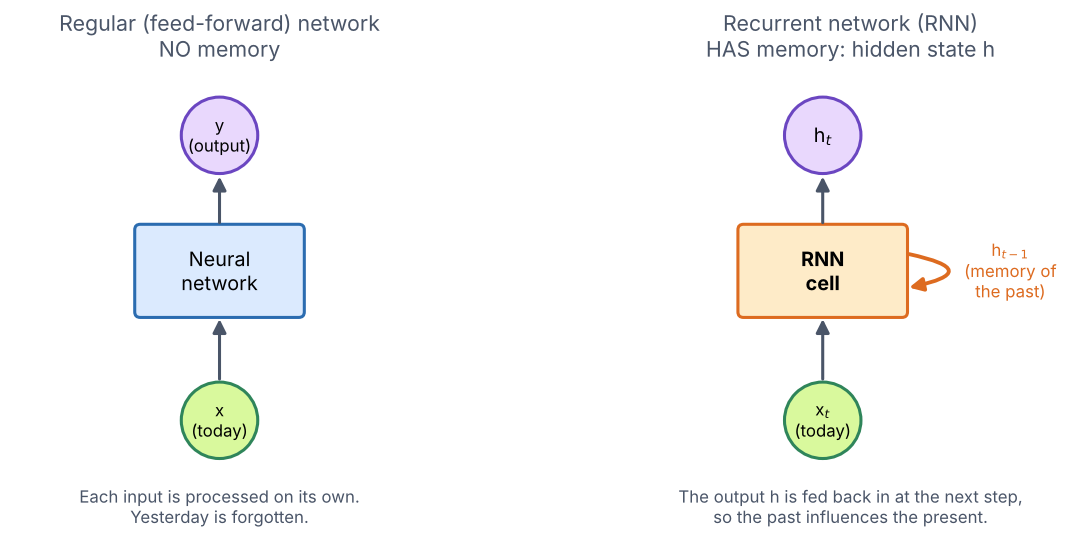

When you read "The river spread over its bank", you know "bank" means a riverside because you remember the word "river".
The hidden state plays the same role for an RNN: it is a short summary of everything read so far.

## A.2 The RNN formula
At each step `t`, the RNN cell combines today's input $x_t$ with the previous memory $h_{t-1}$ to get the new memory $h_t$:

$$h_t = \tanh\left(w_x \cdot x_t \;+\; w_h \cdot h_{t-1} \;+\; b\right)$$

| Symbol | Meaning | In the stock example |
|---|---|---|
| $x_t$ | the input at step `t` | the (scaled) opening price on day `t` |
| $h_{t-1}$ | the memory from the previous step ($h_0 = 0$ at the start) | a summary of all earlier days |
| $w_x$ | weight on the input | how much "today" matters |
| $w_h$ | weight on the memory | how much "the past" matters |
| $b$ | bias | a constant shift |
| $\tanh$ | activation function | keeps the result between −1 and 1 |
| $h_t$ | the new memory (hidden state) | passed on to the next day; after the last day it is used for the prediction |

The same weights $w_x$, $w_h$ and $b$ are used at every step. The RNN doesn't learn separate weights for day 1, day 2 and so on;
it learns one rule for updating its memory and applies it at each step. Training is the process of finding good values for these weights.

In the real model, $x_t$ and $h_t$ are vectors ($h_t$ has 50 numbers because there are 50 units) and the weights are matrices.

## A.3 A small worked example
Take an RNN with one memory unit that reads three days of scaled prices and predicts day 4.

* Inputs (scaled prices, going up): $x_1 = 0.2,\; x_2 = 0.5,\; x_3 = 0.9$
* Weights (assume training already found them): $w_x = 1.0,\; w_h = 0.5,\; b = 0$; output layer: $\hat{y} = 1.1 \cdot h_3$
* Starting memory: $h_0 = 0$

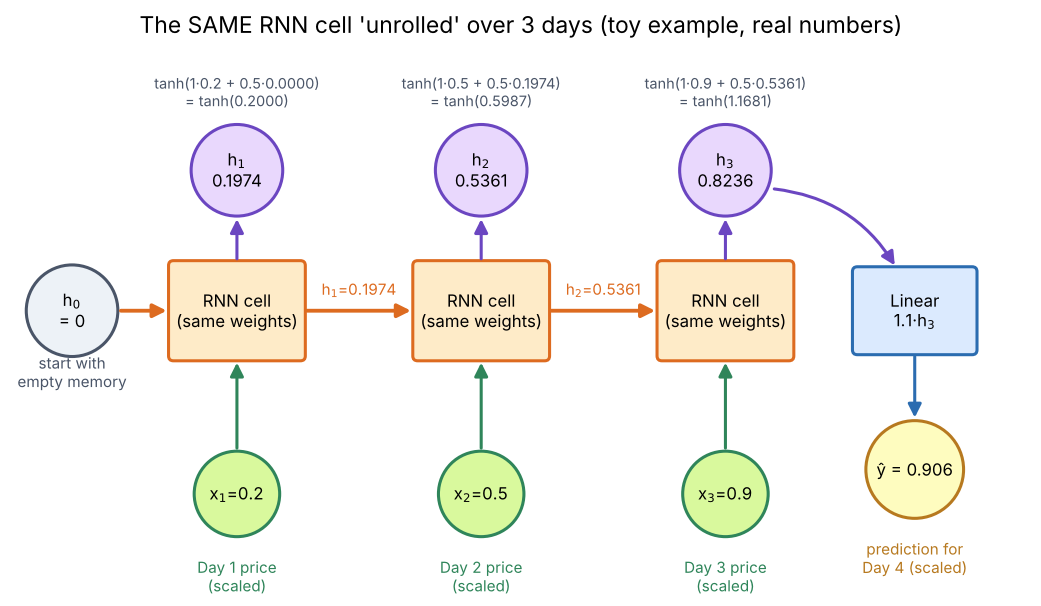

| Step | What happens | Calculation | Result |
|---|---|---|---|
| Day 1 | Read $x_1$; the memory is still empty | $h_1 = \tanh(1.0 \times 0.2 + 0.5 \times 0) = \tanh(0.2000)$ | $h_1 = 0.1974$ |
| Day 2 | Read $x_2$ and use day 1 (through $h_1$) | $h_2 = \tanh(1.0 \times 0.5 + 0.5 \times 0.1974) = \tanh(0.5987)$ | $h_2 = 0.5361$ |
| Day 3 | Read $x_3$ and use days 1–2 (through $h_2$) | $h_3 = \tanh(1.0 \times 0.9 + 0.5 \times 0.5361) = \tanh(1.1681)$ | $h_3 = 0.8236$ |
| Predict | Turn the final memory into a price | $\hat{y} = 1.1 \times 0.8236$ | $\hat{y} = 0.906$ |

$h_3$ depends on all three days: on $x_3$ directly, on $x_2$ through $h_2$, and on $x_1$ through $h_1$ and $h_2$. This chain is how
an RNN remembers earlier inputs. Drawing the loop as a row of copies, as in the figure, is called unrolling the RNN through time.
The prediction 0.906 is a bit higher than the last price (0.9), so this small network expects the upward trend to continue a little.

Inside one cell (Day 2): each input is multiplied by its weight, the results are added, and the sum goes through $\tanh$.

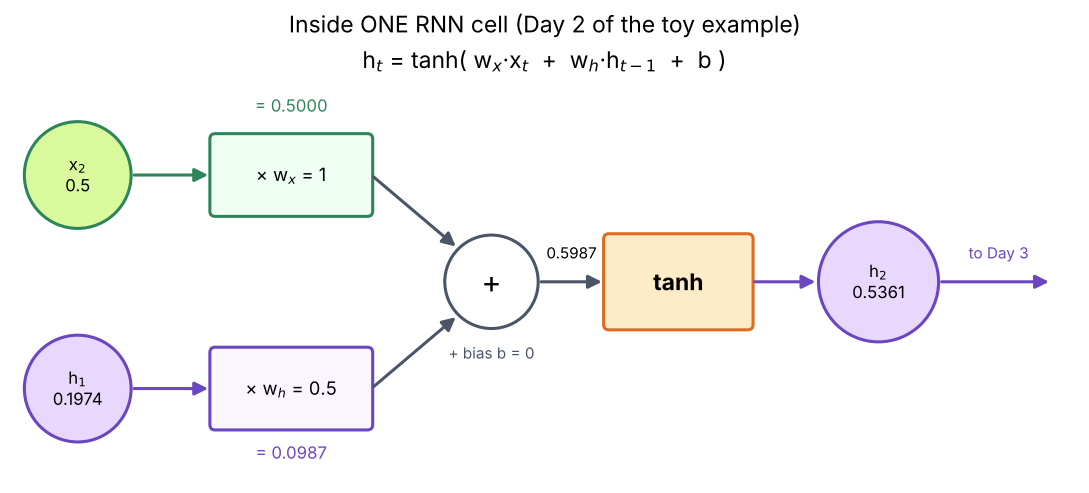

The three steps on the $\tanh$ curve. The output always stays between −1 and 1.

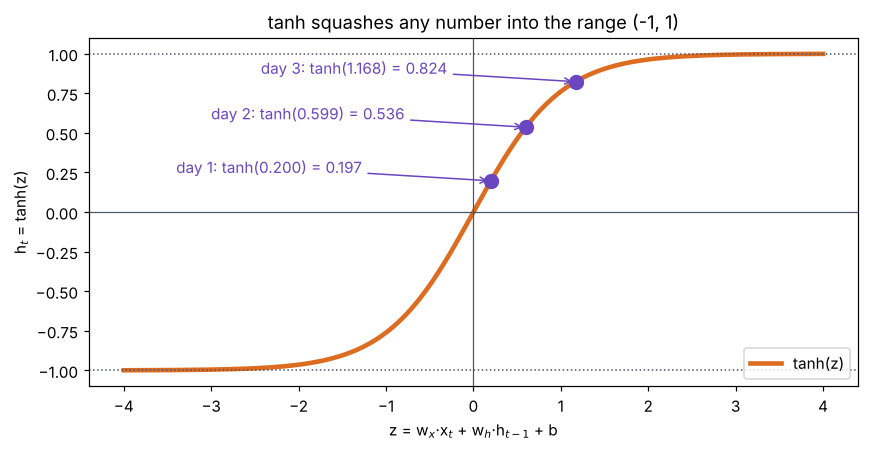

## A.4 Checking the example in code
The cell below repeats the calculation with a simple loop and then with PyTorch's `nn.RNN` layer using the same weights. It also
shows that order matters: the same three prices in falling order give a different memory and a lower prediction.

In [24]:
import math                                   # math.tanh is used for the hand calculation.
import torch                                  # PyTorch, to compare with a real RNN layer.
from torch import nn                          # nn.RNN lives in torch.nn.

x_days = [0.2, 0.5, 0.9]                      # Three days of scaled opening prices (going up).
w_x, w_h, b, w_y = 1.0, 0.5, 0.0, 1.1         # The example weights: input, memory, bias, output.


def tiny_rnn(sequence):  # Runs the one-unit RNN over a sequence and returns its prediction for the next day.
    h = 0.0                                   # h0 = 0: start with an empty memory.
    for t, x in enumerate(sequence, start=1): # Read the sequence one day at a time (t = 1, 2, 3).
        h = math.tanh(w_x * x + w_h * h + b)  # The RNN formula: mix today's input with yesterday's memory.
        print(f"  day {t}: x = {x:.1f} -> h_{t} = {h:.4f}")  # Show the memory after each day.
    return w_y * h                            # Output layer: turn the final memory into a prediction.


print("Rising prices  [0.2, 0.5, 0.9]:")                         # First experiment: upward trend.
print(f"  prediction for day 4 = {tiny_rnn(x_days):.4f}")        # Expect 0.9060, as in the table above.
print("Falling prices [0.9, 0.5, 0.2] (same numbers, reversed):")  # Second experiment: downward trend.
print(f"  prediction for day 4 = {tiny_rnn(x_days[::-1]):.4f}")  # A different (lower) result: the RNN noticed the order.

rnn = nn.RNN(input_size=1, hidden_size=1, batch_first=True)  # A real PyTorch RNN layer: 1 input, 1 memory unit, tanh.
with torch.no_grad():                         # We are setting weights by hand, not training, so gradients are not needed.
    rnn.weight_ih_l0.fill_(w_x)               # Set the input weight to w_x = 1.0.
    rnn.weight_hh_l0.fill_(w_h)               # Set the memory weight to w_h = 0.5.
    rnn.bias_ih_l0.fill_(b)                   # PyTorch has two biases that are added together; set the first to b = 0...
    rnn.bias_hh_l0.fill_(0.0)                 # ...and the second to 0.
    seq = torch.tensor(x_days).reshape(1, 3, 1)  # Shape the prices as (batch = 1, time steps = 3, features = 1).
    outputs, h_last = rnn(seq)                # outputs holds h1, h2, h3; h_last holds h3.
print("nn.RNN hidden states:", outputs.flatten().numpy().round(4))  # Same h1, h2, h3 as the hand calculation.

Rising prices  [0.2, 0.5, 0.9]:
  day 1: x = 0.2 -> h_1 = 0.1974
  day 2: x = 0.5 -> h_2 = 0.5361
  day 3: x = 0.9 -> h_3 = 0.8236
  prediction for day 4 = 0.9060
Falling prices [0.9, 0.5, 0.2] (same numbers, reversed):
  day 1: x = 0.9 -> h_1 = 0.7163
  day 2: x = 0.5 -> h_2 = 0.6953
  day 3: x = 0.2 -> h_3 = 0.4988
  prediction for day 4 = 0.5486
nn.RNN hidden states: [0.1974 0.5361 0.8236]


## A.5 How this connects to the stock model
*Turning a price history into examples.* The price series is cut into many overlapping windows. Each 60-day window is an input `X`,
and the price on the next day is its target `y`.

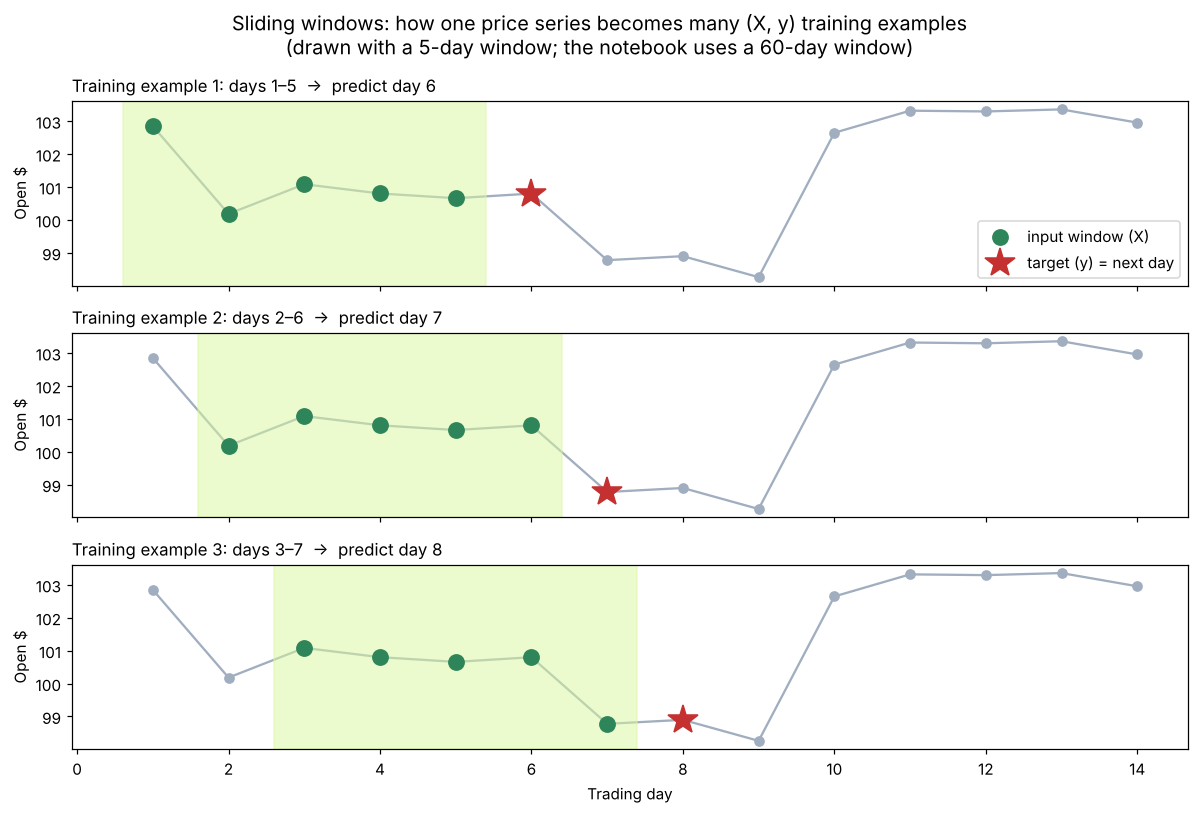

*Reading a window and making one prediction.* The network reads the 60 days one at a time, like the 3-day example. The model stacks
4 RNN layers: layer 1 reads the prices, and each higher layer reads the sequence of memories from the layer below, so it can pick up
more complex patterns. Only the final memory of the top layer (50 numbers summarizing the 60 days) goes into the linear layer, which
outputs one number: the next day's opening price. This setup, with many inputs and one output, is called many-to-one.

What are those 50 numbers? They aren't prices; they're learned features. One might roughly track "the price is rising",
another "the price has been jumpy lately", and so on. Nobody tells the network what each number should mean: it decides
during training, by adjusting its weights so that these features help predict the next price. Keeping only the memory after
day 60 is enough, because that memory already contains information from days 1–59 (the chain shown in A.3). The linear layer
then combines the 50 features $m_1, \dots, m_{50}$ into one number with a weighted sum,
$\text{prediction} = w_1 m_1 + w_2 m_2 + \dots + w_{50} m_{50} + b$, where the weights $w$ and $b$ are also learned.

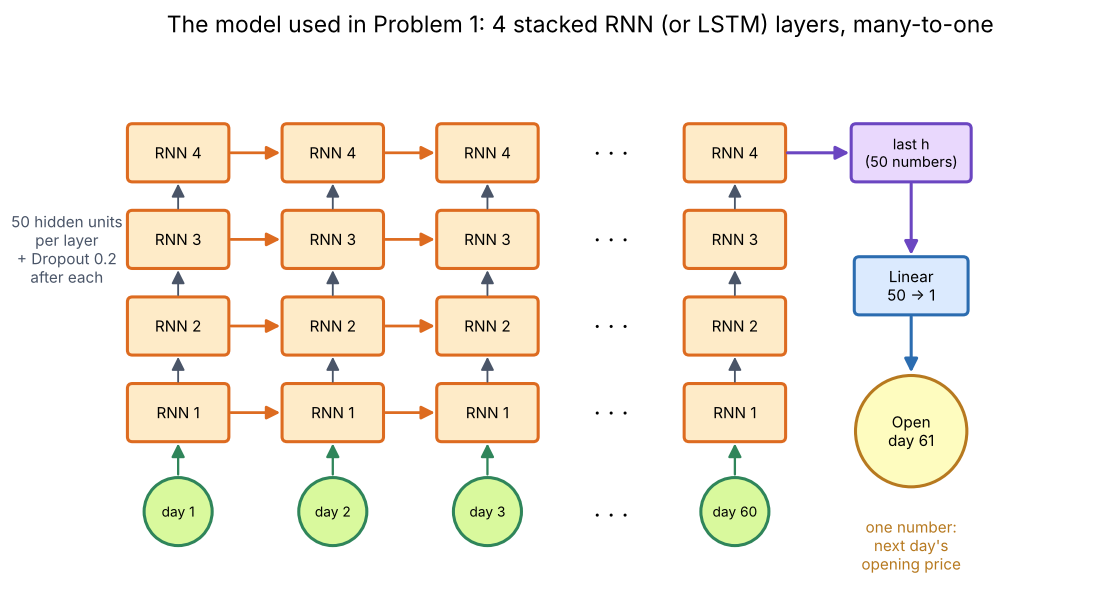

*Learning the weights.* The weights start random, so the first predictions are poor. For each batch the error (MSE) is computed, and
backpropagation through time sends it back through all 60 days to work out how each weight should change. Adam then updates the
weights. After 100 epochs the weights describe a memory-update rule that fits this stock's history.

## A.6 Vanishing gradients and the LSTM
During backpropagation, the learning signal for an early day is multiplied by a factor at every step it travels back. If that factor
is below 1, the signal shrinks quickly. This is the vanishing gradient problem, and it means a plain RNN learns mostly from the last
few days of the window. If the factor is above 1, the signal grows instead (exploding gradients), which is why the RNN training code
clips the gradients.

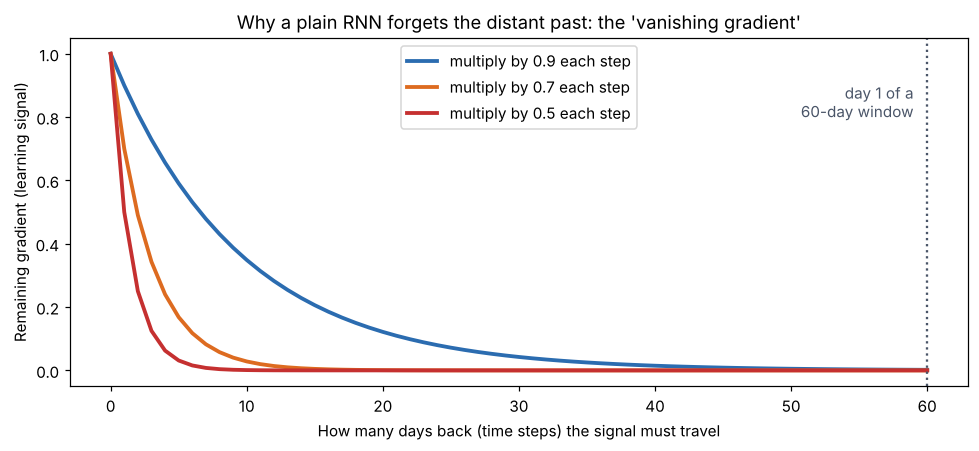

The LSTM (long short-term memory) addresses this with a second memory, the cell state, and three gates. The gates are small learned
switches with values between 0 (closed) and 1 (open). Section A.7 goes through one LSTM cell step by step with numbers.

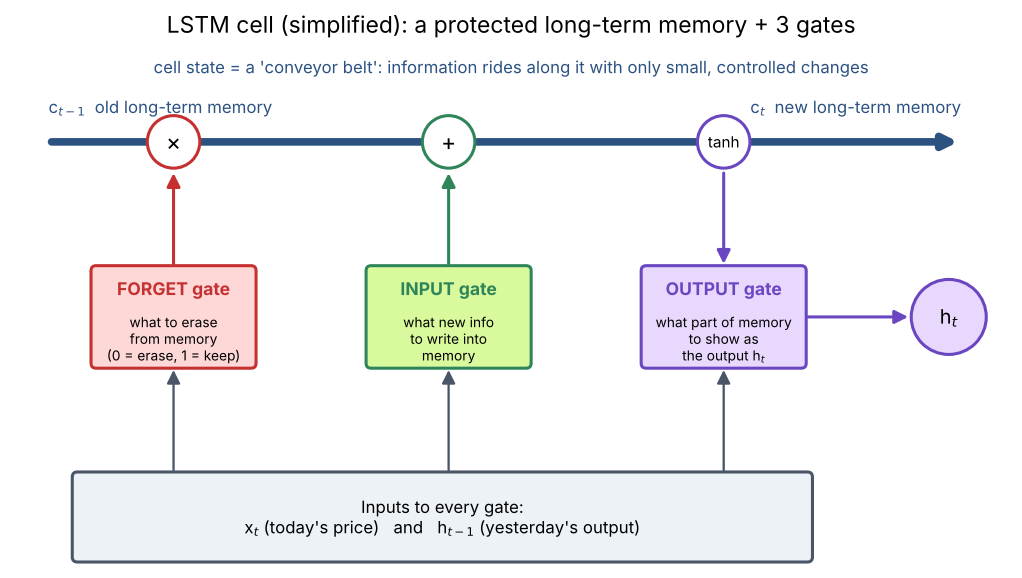

| Gate | What it decides | Stock example |
|---|---|---|
| Forget gate | Which parts of the old memory to erase | "The September dip is over, so forget it." |
| Input gate | Which parts of today's information to store | "Today's big jump is important, so remember it." |
| Output gate | Which parts of the memory to output as $h_t$ | "Pass the current trend to the next layer." |

The cell state is updated mainly by adding new information instead of repeatedly multiplying, so information and its learning signal
can last across many time steps. In Problem 1 the LSTM did reach a lower training error than the RNN
(about 0.0008 vs 0.0011), but it was less accurate on the 23 test days (MAE about \$19.5 vs \$14.6).

## A.7 Inside an LSTM cell, step by step
Each day `t`, an LSTM cell receives today's input $x_t$, yesterday's output $h_{t-1}$ and yesterday's long-term memory $c_{t-1}$.
It then does four small calculations and two updates. $\sigma$ is the sigmoid function: it squashes any number into the range
0 to 1, so each gate works like a dial, where 0 means "let nothing through" and 1 means "let everything through".

| # | Part | Formula | What it does |
|---|---|---|---|
| 1 | Forget gate | $f_t = \sigma(w_f x_t + u_f h_{t-1} + b_f)$ | how much of the old memory to keep (0–1) |
| 2 | Input gate | $i_t = \sigma(w_i x_t + u_i h_{t-1} + b_i)$ | how much of the new information to store (0–1) |
| 3 | Candidate | $g_t = \tanh(w_g x_t + u_g h_{t-1} + b_g)$ | the new information itself (−1 to 1) |
| 4 | Output gate | $o_t = \sigma(w_o x_t + u_o h_{t-1} + b_o)$ | how much of the memory to output (0–1) |
| 5 | New long-term memory | $c_t = f_t \cdot c_{t-1} + i_t \cdot g_t$ | keep part of the old memory and add part of the new information |
| 6 | New output | $h_t = o_t \cdot \tanh(c_t)$ | what the cell passes to the next day and to the next layer |

Each of the four parts has its own weights ($w$ for today's input, $u$ for yesterday's output, $b$ for the bias), all learned in
training. That is why the LSTM in Problem 1 has about 4 times as many weights as the RNN (71,851 vs 18,001): it has four sets of
weights where the RNN has one.

### Worked example
The same three days as the RNN example in Section A.3 (scaled prices 0.2, 0.5, 0.9), with one memory unit and $h_0 = c_0 = 0$.
Assume training found these weights:

| Part | $w$ (today's input) | $u$ (yesterday's output) | $b$ (bias) |
|---|---|---|---|
| Forget gate $f$ | 0.5 | 0.5 | 1.0 |
| Input gate $i$ | 1.0 | 0.5 | 0 |
| Candidate $g$ | 1.0 | 1.0 | 0 |
| Output gate $o$ | 0.5 | 1.0 | 0.5 |

Day 2 in detail ($x_2 = 0.5$, and from day 1: $h_1 = 0.0698$, $c_1 = 0.1085$):
* Forget gate: $f_2 = \sigma(0.5 \times 0.5 + 0.5 \times 0.0698 + 1.0) = \sigma(1.2849) = 0.7833$, so 78% of the old memory is kept.
* Input gate: $i_2 = \sigma(1.0 \times 0.5 + 0.5 \times 0.0698) = \sigma(0.5349) = 0.6306$, so 63% of the new information is stored.
* Candidate: $g_2 = \tanh(1.0 \times 0.5 + 1.0 \times 0.0698) = \tanh(0.5698) = 0.5152$.
* Output gate: $o_2 = \sigma(0.5 \times 0.5 + 1.0 \times 0.0698 + 0.5) = \sigma(0.8198) = 0.6942$.
* New memory: $c_2 = 0.7833 \times 0.1085 + 0.6306 \times 0.5152 = 0.0850 + 0.3249 = 0.4099$.
* New output: $h_2 = 0.6942 \times \tanh(0.4099) = 0.6942 \times 0.3884 = 0.2696$.

All three days:

| Day | $x_t$ | $f_t$ | $i_t$ | $g_t$ | $o_t$ | kept $f_t c_{t-1}$ | added $i_t g_t$ | $c_t$ | $h_t$ |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 0.2 | 0.7503 | 0.5498 | 0.1974 | 0.6457 | 0.0000 | 0.1085 | 0.1085 | 0.0698 |
| 2 | 0.5 | 0.7833 | 0.6306 | 0.5152 | 0.6942 | 0.0850 | 0.3249 | 0.4099 | 0.2696 |
| 3 | 0.9 | 0.8299 | 0.7378 | 0.8242 | 0.7720 | 0.3402 | 0.6081 | 0.9483 | 0.5705 |

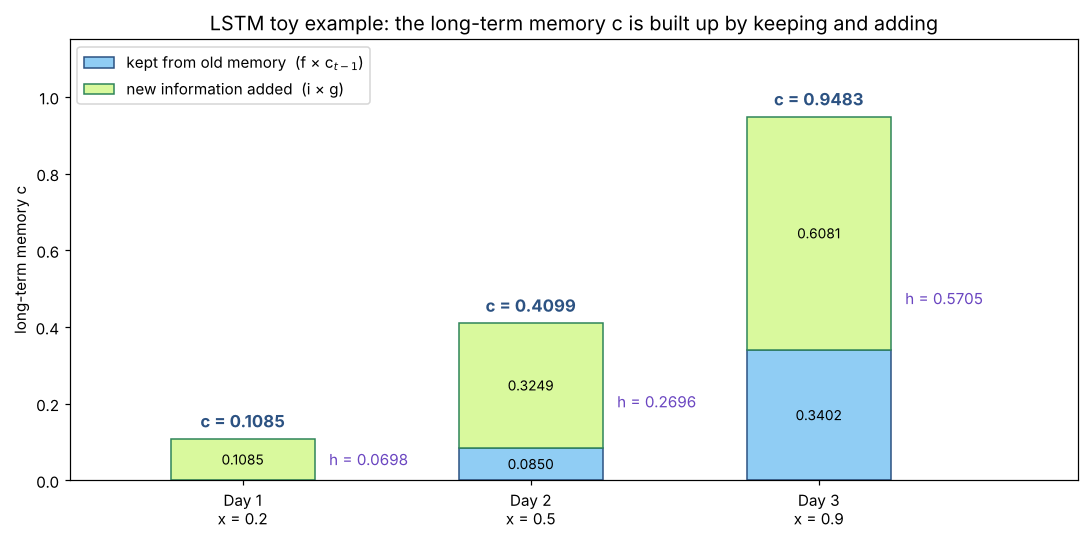

### Why this helps with long sequences
In the plain RNN, the memory is rebuilt every day by passing it through $\tanh$ together with the new input, so old information
is gradually overwritten and the learning signal shrinks at every step (Section A.6). In the LSTM the long-term memory is carried
forward by $c_t = f_t \cdot c_{t-1} + i_t \cdot g_t$. When the forget gate is close to 1, the old memory passes through almost
unchanged: in the example, 83% of the day-2 memory is still in $c_3$ (0.3402 of 0.4099). During training the learning signal travels
back along the same path and is multiplied only by $f_t$, so the network can keep it alive over many days by keeping the forget gate open.

The cell below repeats the calculation by hand and then with PyTorch's `nn.LSTM`, using the same weights.

In [25]:
import math                       # math.exp and math.tanh for the hand calculation.
import torch                      # PyTorch, to compare with a real LSTM layer.
from torch import nn              # nn.LSTM lives in torch.nn.


def sigmoid(z):                   # Squashes any number into the range 0-1 (used by the gates).
    return 1 / (1 + math.exp(-z))


x_days = [0.2, 0.5, 0.9]          # The same three scaled prices as in the RNN example.
# Weights of each gate: (w for today's input, u for yesterday's output, b for the bias).
weights = {"f": (0.5, 0.5, 1.0), "i": (1.0, 0.5, 0.0), "g": (1.0, 1.0, 0.0), "o": (0.5, 1.0, 0.5)}

h, c = 0.0, 0.0                   # Start with an empty output (h) and long-term memory (c).
for t, x in enumerate(x_days, start=1):  # Read the days one by one.
    # Weighted sum for each gate: w * today's input + u * yesterday's output + b.
    z = {k: w * x + u * h + b for k, (w, u, b) in weights.items()}
    f, i, o = sigmoid(z["f"]), sigmoid(z["i"]), sigmoid(z["o"])  # The three gates (0 to 1).
    g = math.tanh(z["g"])         # The new information (-1 to 1).
    c = f * c + i * g             # Keep part of the old memory and add part of the new information.
    h = o * math.tanh(c)          # Output part of the memory.
    print(f"day {t}: f={f:.4f} i={i:.4f} g={g:.4f} o={o:.4f} -> c_{t}={c:.4f}, h_{t}={h:.4f}")

# The same calculation with PyTorch's nn.LSTM (1 input value, 1 memory unit).
# PyTorch stores the four parts in the order: input gate, forget gate, candidate, output gate.
lstm = nn.LSTM(input_size=1, hidden_size=1, batch_first=True)
with torch.no_grad():             # We set the weights by hand, so no gradients are needed.
    lstm.weight_ih_l0.copy_(torch.tensor([[1.0], [0.5], [1.0], [0.5]]))  # w for i, f, g, o.
    lstm.weight_hh_l0.copy_(torch.tensor([[0.5], [0.5], [1.0], [1.0]]))  # u for i, f, g, o.
    lstm.bias_ih_l0.copy_(torch.tensor([0.0, 1.0, 0.0, 0.5]))            # b for i, f, g, o.
    lstm.bias_hh_l0.zero_()       # PyTorch has a second bias; set it to 0.
    seq = torch.tensor(x_days).reshape(1, 3, 1)  # Shape (batch = 1, days = 3, values per day = 1).
    outputs, (h_last, c_last) = lstm(seq)        # outputs = h for every day; c_last = final memory.
print("nn.LSTM outputs h:", outputs.flatten().numpy().round(4))      # Same h_1, h_2, h_3 as above.
print("nn.LSTM final memory c_3:", c_last.flatten().numpy().round(4))  # Same c_3 as above.

day 1: f=0.7503 i=0.5498 g=0.1974 o=0.6457 -> c_1=0.1085, h_1=0.0698
day 2: f=0.7833 i=0.6306 g=0.5152 o=0.6942 -> c_2=0.4099, h_2=0.2696
day 3: f=0.8299 i=0.7378 g=0.8242 o=0.7720 -> c_3=0.9483, h_3=0.5705
nn.LSTM outputs h: [0.0698 0.2696 0.5705]
nn.LSTM final memory c_3: [0.9483]


## A.8 Layered (stacked) LSTMs
A layered LSTM puts several LSTM layers on top of each other. Layer 1 reads the prices day by day, as in A.7. Layer 2 does not
read the prices: it reads the **sequence of outputs of layer 1**, one per day, and so on. Each layer has its own weights and its
own memory, and only the output of the **top** layer on the last day goes to the Linear layer that makes the prediction.

The models in Problems 1 and 2 have 4 LSTM (or RNN) layers of 50 units each. In the code this is simply
`x, _ = self.lstm1(x)`, then `x, _ = self.lstm2(x)`, and so on: the full sequence that comes out of one layer is the input of the next.

**Why stack layers?** One layer turns the prices into a memory of what happened recently. A second layer works with that
memory instead of the raw prices, so it can learn patterns of patterns (for example "the price has risen for a while, and the rise
is slowing down"). This is the same idea as stacking layers in any deep network. More layers give the model more capacity, but also
more weights to learn, so they need more data and training time and can overfit more easily (the dropout between the layers helps).

### Worked example
Two layers with one unit each, the same three prices (0.2, 0.5, 0.9). Layer 1 is exactly the LSTM from A.7. Layer 2 uses the same
formulas with its own weights (forget: $w=1.0, u=0.5, b=1.0$; input: $w=1.5, u=0.5, b=0$; candidate: $w=2.0, u=1.0, b=0$;
output: $w=1.0, u=1.0, b=0.5$), and its input on day $t$ is layer 1's output $h^{(1)}_t$.

| Day | price $x_t$ | layer 1 output $h^{(1)}_t$ (= input of layer 2) | layer 2 memory $c^{(2)}_t$ | layer 2 output $h^{(2)}_t$ |
|---|---|---|---|---|
| 1 | 0.2 | 0.0698 | 0.0730 | 0.0465 |
| 2 | 0.5 | 0.2696 | 0.3762 | 0.2492 |
| 3 | 0.9 | 0.5705 | 0.9601 | 0.5874 |

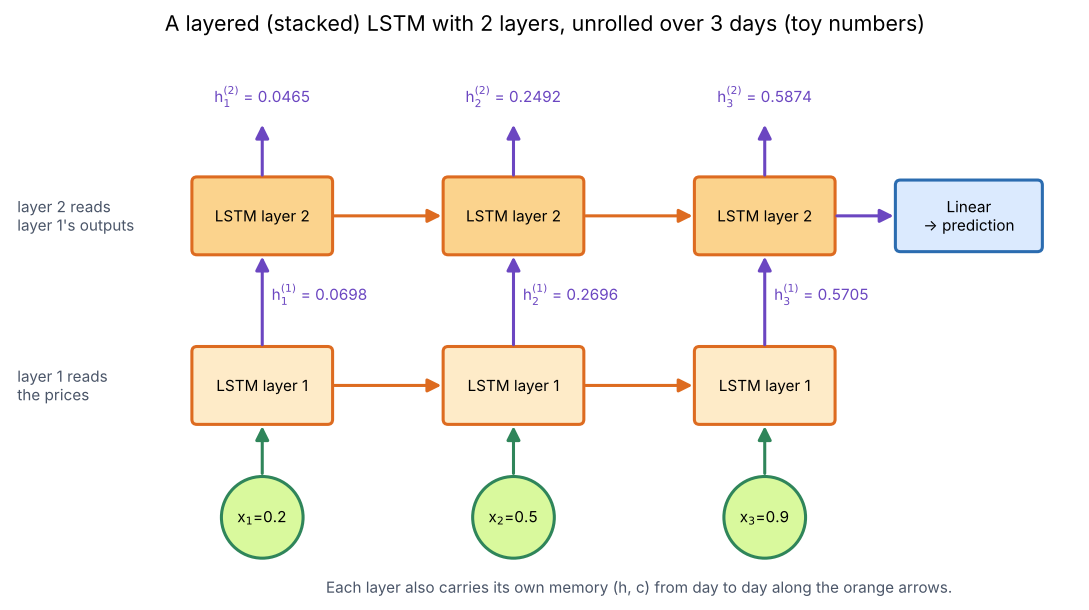

Only $h^{(2)}_3 = 0.5874$, the top layer's output on the last day, is passed to the Linear layer (in Problem 1 this is the line
`x = x[:, -1, :]`). The cell below checks the numbers with two PyTorch LSTM layers.

In [ ]:
# Check the layered example: layer 2 reads layer 1's outputs, as in the Problem 1 models.
import torch            # PyTorch.
from torch import nn    # nn.LSTM.

# PyTorch keeps the four parts of an LSTM in the order: input gate, forget gate, candidate, output gate.
def set_lstm_weights(lstm, w, u, b):
    with torch.no_grad():  # Setting weights by hand, so no gradients are needed.
        lstm.weight_ih_l0.copy_(torch.tensor(w).reshape(4, 1))  # w for i, f, g, o (today's input).
        lstm.weight_hh_l0.copy_(torch.tensor(u).reshape(4, 1))  # u for i, f, g, o (yesterday's output).
        lstm.bias_ih_l0.copy_(torch.tensor(b))                  # b for i, f, g, o.
        lstm.bias_hh_l0.zero_()                                 # PyTorch's second bias: set to 0.

layer1 = nn.LSTM(1, 1, batch_first=True)  # Layer 1: reads the price (1 value per day).
layer2 = nn.LSTM(1, 1, batch_first=True)  # Layer 2: reads layer 1's output (1 value per day).
set_lstm_weights(layer1, [1.0, 0.5, 1.0, 0.5], [0.5, 0.5, 1.0, 1.0], [0.0, 1.0, 0.0, 0.5])  # From A.7.
set_lstm_weights(layer2, [1.5, 1.0, 2.0, 1.0], [0.5, 0.5, 1.0, 1.0], [0.0, 1.0, 0.0, 0.5])  # New weights.

prices = torch.tensor([0.2, 0.5, 0.9]).reshape(1, 3, 1)  # (batch 1, 3 days, 1 value per day)
with torch.no_grad():
    out1, _ = layer1(prices)  # Layer 1 outputs for every day.
    out2, _ = layer2(out1)    # Layer 2 reads them (the same "x, _ = self.lstm2(x)" as in Problem 1).
print("layer 1 outputs:", out1.flatten().numpy().round(4))  # Same as the A.7 example.
print("layer 2 outputs:", out2.flatten().numpy().round(4))  # The last one goes to the Linear layer.

layer 1 outputs: [0.0698 0.2696 0.5705]
layer 2 outputs: [0.0465 0.2492 0.5874]


## A.9 Bidirectional RNNs
A normal RNN reads a sequence in one direction only, so its output at step $t$ knows about steps $1 \dots t$ but nothing about what
comes after. For text this is often not enough. In "the **right** arm", "the **right** person" and "the **right** to criticize", the
meaning of "right" depends on the words that come **after** it.

A **bidirectional** RNN runs two RNNs on the same input: one reads it from left to right, the other from right to left. At every
step their two outputs are put side by side (concatenated), so each output knows about the whole sequence, both before and after:

$$\overrightarrow{h}_t = \tanh(w_x x_t + w_h \overrightarrow{h}_{t-1} + b), \qquad
\overleftarrow{h}_t = \tanh(w_x x_t + w_h \overleftarrow{h}_{t+1} + b), \qquad
\text{output}_t = [\overrightarrow{h}_t,\ \overleftarrow{h}_t]$$

(the two directions normally have their own, different weights). With 50 units per direction, a bidirectional layer outputs 100
numbers per step.

### Worked example
The RNN from A.3 ($w_x = 1.0$, $w_h = 0.5$, $b = 0$), used in both directions on the prices 0.2, 0.5, 0.9:

| Day | price | forward (reads day 1 → 3) | backward (reads day 3 → 1) | output = both joined |
|---|---|---|---|---|
| 1 | 0.2 | 0.1974 | 0.4988 | [0.1974, 0.4988] |
| 2 | 0.5 | 0.5361 | 0.6953 | [0.5361, 0.6953] |
| 3 | 0.9 | 0.8236 | 0.7163 | [0.8236, 0.7163] |

The forward numbers are the ones from A.3. The backward numbers are the "falling prices" run from A.4, read in reverse order: the
backward RNN starts on day 3 (0.9 → 0.7163), then day 2 (0.6953), then day 1 (0.4988). On day 1, the output now contains
information about days 2 and 3 as well.

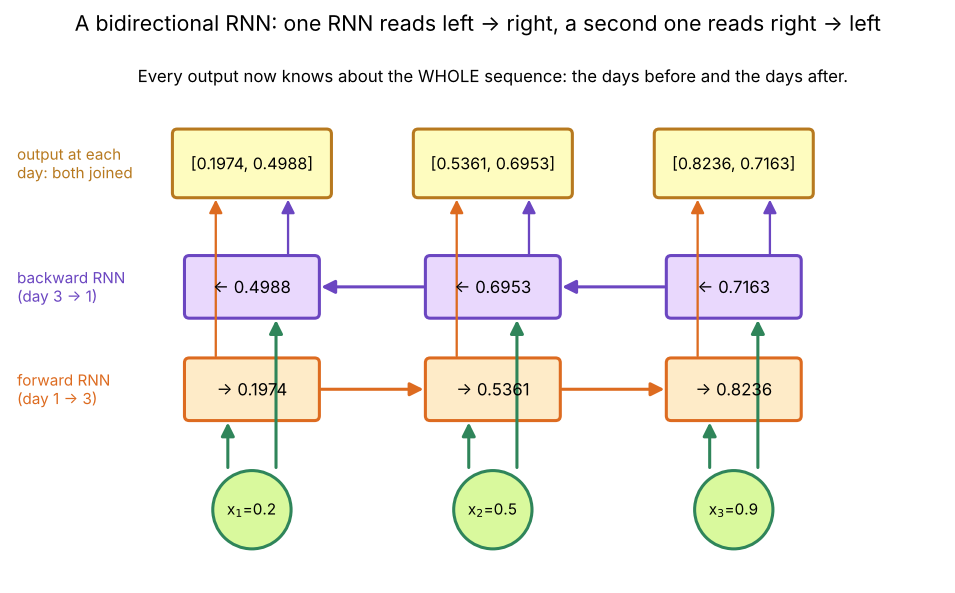

**When can it be used?** Only when the whole sequence is known before the output is needed:
* Yes: understanding a whole sentence (classifying it, or the **encoder** of a translator, which has the full English sentence).
* No: forecasting, as in Problems 1 and 2. To predict tomorrow's price, the backward direction would need prices that are not known
  yet, so it would be cheating. The same is true for the **decoder** of a translator, which writes the translation word by word.

In [ ]:
# Check the bidirectional example with PyTorch: bidirectional=True runs a second RNN backwards.
import torch            # PyTorch.
from torch import nn    # nn.RNN.

rnn = nn.RNN(input_size=1, hidden_size=1, batch_first=True, bidirectional=True)
with torch.no_grad():  # Same weights as the A.3 example, for both directions.
    for name, parameter in rnn.named_parameters():
        if "weight_ih" in name:
            parameter.fill_(1.0)  # w_x = 1.0 (forward and backward).
        elif "weight_hh" in name:
            parameter.fill_(0.5)  # w_h = 0.5 (forward and backward).
        else:
            parameter.fill_(0.0)  # Biases = 0.
    outputs, _ = rnn(torch.tensor([0.2, 0.5, 0.9]).reshape(1, 3, 1))  # (batch 1, 3 days, 1 value)
print("output shape:", tuple(outputs.shape))  # (1, 3, 2): 2 numbers per day (forward, backward).
for day, (forward, backward) in enumerate(outputs[0].numpy(), start=1):
    print(f"day {day}: forward {forward:.4f}, backward {backward:.4f}")

output shape: (1, 3, 2)
day 1: forward 0.1974, backward 0.4988
day 2: forward 0.5361, backward 0.6953
day 3: forward 0.8236, backward 0.7163


## A.10 Encoder–decoder models for machine translation (NMT)
A translator must turn a sequence of English words into a sequence of Spanish words, and the two sentences can have different
lengths and word orders ("I like soccer." has 4 tokens, "me gusta el fútbol." has 5). An **encoder–decoder** (also called seq2seq)
model splits the job between two networks:

1. **Encoder** (an LSTM): reads the English sentence word by word. Its final memory $(h, c)$ is the **context**: a fixed-size
   summary of the whole sentence (in Problem 3, 512 numbers for $h$ and 512 for $c$).
2. **Decoder** (a second LSTM, with its own weights): starts from the context and writes the Spanish sentence one word at a time.
   At each step it gives a score to every word of the Spanish vocabulary, and the best word is chosen.

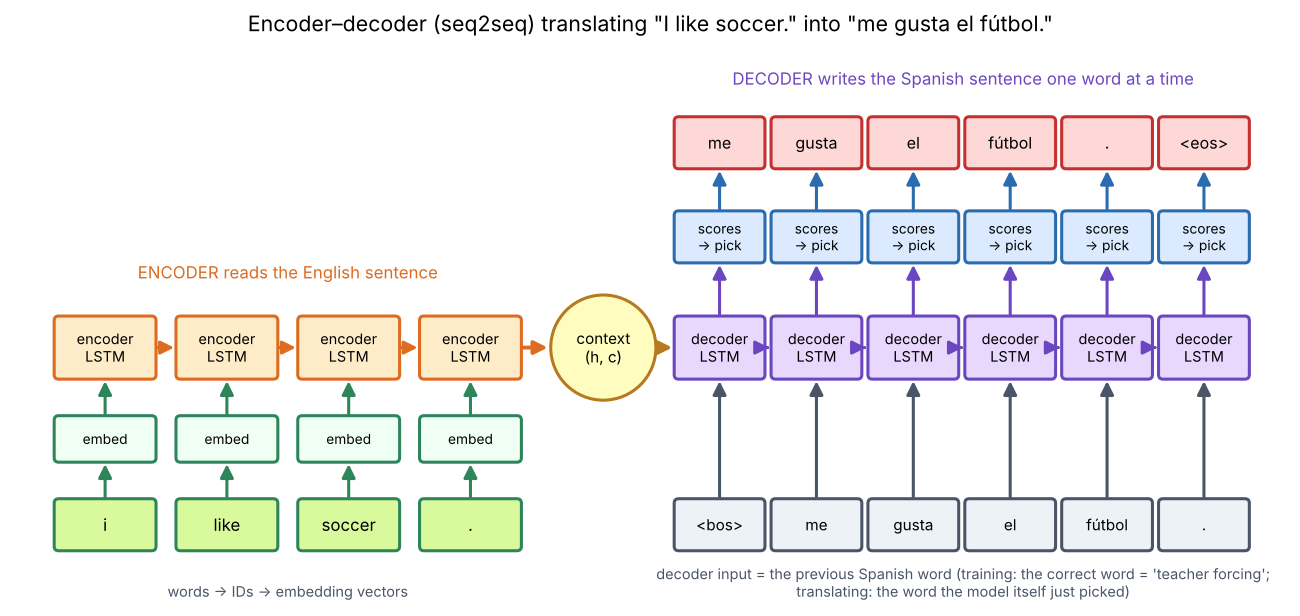

### Step by step for "I like soccer." → "me gusta el fútbol."
1. **Tokens.** The sentence is split into lowercase tokens: `["i", "like", "soccer", "."]`.
2. **IDs.** Each token is replaced by its number in the English vocabulary. Only the `VOCAB_SIZE` most frequent training words have
   a number; every other word becomes `<unk>` (ID 1). With the toy 8-word vocabulary in the cell below, "I like cheese." becomes
   `[4, 5, 1, 7]`: the model never sees the word "cheese", only "some unknown word". This is exactly what Problem 3 changes.
3. **Embeddings.** Each ID selects a learned vector (128 numbers in Problem 3). Words used in similar ways end up with similar vectors.
4. **Encoder.** The encoder LSTM reads the 4 vectors (like the RNN/LSTM examples in A.3 and A.7) and hands its final $(h, c)$ to the decoder.
5. **Decoder, training (teacher forcing).** The decoder receives the correct Spanish sentence shifted by one position and must
   predict the next word at every position:

   | Decoder receives | `<bos>` | me | gusta | el | fútbol | . |
   |---|---|---|---|---|---|---|
   | Must predict | me | gusta | el | fútbol | . | `<eos>` |

   Giving it the correct previous word (instead of its own guess) is called **teacher forcing**; it makes training faster and more stable.
6. **Scores → word.** The decoder's output is turned into one score (logit) per Spanish word. Softmax turns the scores into
   probabilities, and the loss (cross-entropy) is small when the correct word gets a high probability.
7. **Decoder, translating (greedy decoding).** A new sentence has no correct translation to feed in, so the decoder starts with
   `<bos>`, picks the most likely word, feeds that word back in as the next input, and repeats until it produces `<eos>`. One wrong
   word can lead to more wrong words, which is why translations are usually worse than the teacher-forced accuracy suggests.

**Limits of this simple model.** The whole sentence must fit into one fixed-size context, which is hard for long sentences (the
lecture's next step, *attention*, lets the decoder look back at every encoder step). And any word outside the vocabulary becomes
`<unk>`, on both the English and the Spanish side. The cell below shows steps 2 and 6 with toy numbers.

In [ ]:
# A tiny version of the first steps of the translator: tokens -> IDs (with <unk>) and choosing a word.
import torch  # PyTorch (for softmax).

english_vocab = ["<pad>", "<unk>", "<bos>", "<eos>", "i", "like", "soccer", "."]  # A toy 8-word vocabulary.
stoi = {word: index for index, word in enumerate(english_vocab)}  # Word -> ID.
for sentence in (["i", "like", "soccer", "."], ["i", "like", "cheese", "."]):
    ids = [stoi.get(word, stoi["<unk>"]) for word in sentence]  # Unknown words get ID 1 (<unk>).
    print(f"{' '.join(sentence):18s} -> IDs {ids}")

# The decoder gives one score (logit) to every Spanish word; softmax turns the scores into
# probabilities that add up to 1, and greedy decoding picks the most likely word.
spanish_vocab = ["<pad>", "<unk>", "<bos>", "<eos>", "me", "gusta", "el", "fútbol"]
scores = torch.tensor([0.1, 0.3, -5.0, 0.2, 3.0, 1.2, 0.4, 0.6])  # Example scores for the first word.
probabilities = torch.softmax(scores, dim=0)
for word, p in zip(spanish_vocab, probabilities):
    print(f"{word:8s} {p:.3f}")
print("greedy choice:", spanish_vocab[int(probabilities.argmax())])  # -> "me"

i like soccer .    -> IDs [4, 5, 6, 7]
i like cheese .    -> IDs [4, 5, 1, 7]
<pad>    0.036
<unk>    0.044
<bos>    0.000
<eos>    0.040
me       0.661
gusta    0.109
el       0.049
fútbol   0.060
greedy choice: me
